In [2]:
# Step 1 of the code pipeline

In [3]:
# Data Loading & Preprocessing (MODIFIED - Fully Numerical Output)
# Cell 1: Imports & Configuration
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# Load your dataset
# df = pd.read_csv('IoTID20_XAI2.csv')
df = pd.read_csv('NF-BoT-IoT-v2-5%.csv')

print("=" * 60)
print("STAGE 1: DATA PREPROCESSING (FULLY NUMERICAL OUTPUT)")
print("=" * 60)

# Check if 'Attack' column exists
if 'Attack' not in df.columns:
    print("Error: 'Attack' column not found. Available columns:", df.columns.tolist())
else:
    # ============================================================================
    # STEP 1: Initial Data Cleaning
    # ============================================================================
    print("\n[Step 1] Initial data cleaning...")

    # Fill missing values in numeric columns
    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())

    # Fill missing values in non-numeric columns with mode or 'unknown'
    non_numeric_cols = df.select_dtypes(exclude=['float64', 'int64']).columns
    for col in non_numeric_cols:
        if col != 'Attack':  # Don't fill Attack column yet
            # Use mode for categorical columns
            mode_val = df[col].mode()
            if len(mode_val) > 0:
                df[col] = df[col].fillna(mode_val[0])
            else:
                df[col] = df[col].fillna('unknown')

    # Remove duplicates
    df.drop_duplicates(inplace=True)
    print(f"  Dataset shape after cleansing: {df.shape}")

    # ============================================================================
    # STEP 2: Handle Non-Numeric Columns (IP addresses, protocols, etc.)
    # ============================================================================
    print("\n[Step 2] Encoding categorical/non-numeric columns...")

    # Identify non-numeric columns (excluding the target 'Attack' column)
    non_numeric_cols = df.select_dtypes(exclude=['float64', 'int64']).columns.tolist()
    if 'Attack' in non_numeric_cols:
        non_numeric_cols.remove('Attack')

    print(f"  Non-numeric columns found: {non_numeric_cols}")

    # Create a copy of the dataframe for encoding
    df_encoded = df.copy()

    # Encode each non-numeric column
    encoders = {}
    for col in non_numeric_cols:
        print(f"  Encoding column: '{col}'")

        # Check if column contains IP addresses
        sample_val = df[col].dropna().iloc[0] if len(df[col].dropna()) > 0 else ''
        if isinstance(sample_val, str) and '.' in sample_val and sample_val.replace('.', '').isdigit():
            print(f"    → Detected IP addresses in '{col}', converting to integers...")
            # Convert IP to integer
            def ip_to_int(ip):
                try:
                    parts = str(ip).split('.')
                    if len(parts) == 4:
                        return (int(parts[0]) << 24) + (int(parts[1]) << 16) + (int(parts[2]) << 8) + int(parts[3])
                    else:
                        return 0
                except:
                    return 0

            df_encoded[col] = df[col].apply(ip_to_int)
        else:
            # Use LabelEncoder for regular categorical data
            le = LabelEncoder()
            # Convert to string and fill NaN
            col_clean = df[col].astype(str).fillna('unknown')
            df_encoded[col] = le.fit_transform(col_clean)
            encoders[col] = le
            print(f"    → Encoded {len(le.classes_)} unique categories")

    # ============================================================================
    # STEP 3: Handle Port Numbers (ensure they're numeric)
    # ============================================================================
    print("\n[Step 3] Ensuring port numbers are numeric...")

    # Common port column names
    port_columns = ['port', 'sport', 'dport', 'src_port', 'dst_port', 'source_port', 'destination_port']

    for col in port_columns:
        if col in df_encoded.columns:
            print(f"  Converting '{col}' to numeric...")
            df_encoded[col] = pd.to_numeric(df_encoded[col], errors='coerce').fillna(0).astype(int)

    # ============================================================================
    # STEP 4: Handle Protocol Types
    # ============================================================================
    print("\n[Step 4] Encoding protocol types...")

    # Common protocol column names
    protocol_columns = ['proto', 'protocol', 'Protocol', 'PROTO']

    for col in protocol_columns:
        if col in df_encoded.columns:
            print(f"  Encoding '{col}'...")
            # Protocol mapping (common protocols)
            protocol_map = {
                'tcp': 6, 'TCP': 6, '6': 6,
                'udp': 17, 'UDP': 17, '17': 17,
                'icmp': 1, 'ICMP': 1, '1': 1,
                'igmp': 2, 'IGMP': 2, '2': 2,
                'ipv4': 4, 'IPv4': 4,
                'ipv6': 41, 'IPv6': 41
            }

            # Try to map protocols to numbers
            def map_protocol(val):
                try:
                    val_str = str(val).lower()
                    if val_str in protocol_map:
                        return protocol_map[val_str]
                    else:
                        # Try to convert to int directly
                        return int(val)
                except:
                    return 0  # Default for unknown protocols

            df_encoded[col] = df_encoded[col].apply(map_protocol)
            print(f"    → Mapped to protocol numbers")

    # ============================================================================
    # STEP 5: Handle Flags and Other Categorical Data
    # ============================================================================
    print("\n[Step 5] Encoding remaining categorical data...")

    # Identify any remaining object/string columns (excluding target)
    remaining_object_cols = df_encoded.select_dtypes(include=['object']).columns.tolist()
    if 'Attack' in remaining_object_cols:
        remaining_object_cols.remove('Attack')

    for col in remaining_object_cols:
        print(f"  Encoding remaining categorical column: '{col}'")
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
        encoders[col] = le

    # ============================================================================
    # STEP 6: Verify all features are now numeric
    # ============================================================================
    print("\n[Step 6] Verifying numeric conversion...")

    # Separate features and target
    X = df_encoded.drop('Attack', axis=1)
    y = df_encoded['Attack']

    # Check if any non-numeric columns remain in X
    non_numeric_in_X = X.select_dtypes(exclude=['float64', 'int64']).columns.tolist()
    if non_numeric_in_X:
        print(f"  WARNING: Still have non-numeric columns: {non_numeric_in_X}")
        # Force convert any remaining object columns
        for col in non_numeric_in_X:
            print(f"    Forcing conversion of '{col}'")
            X[col] = pd.to_numeric(X[col], errors='coerce').fillna(0)
    else:
        print("  ✓ All features are now numeric!")

    # ============================================================================
    # STEP 7: Normalize numeric features
    # ============================================================================
    print("\n[Step 7] Normalizing numeric features with MinMaxScaler...")

    # Get all numeric columns (should be all columns now)
    numeric_features = X.select_dtypes(include=['float64', 'int64']).columns

    # Check for NaN or Inf values
    if X[numeric_features].isnull().any().any():
        print("  Handling remaining NaN values...")
        X[numeric_features] = X[numeric_features].fillna(X[numeric_features].mean())

    if (X[numeric_features] == np.inf).any().any() or (X[numeric_features] == -np.inf).any().any():
        print("  Handling Inf values...")
        X[numeric_features] = X[numeric_features].replace([np.inf, -np.inf], 0)

    # Initialize and apply MinMaxScaler
    scaler = MinMaxScaler()
    X_scaled = X.copy()
    X_scaled[numeric_features] = scaler.fit_transform(X[numeric_features])

    print(f"  Normalized {len(numeric_features)} features to range [0, 1]")

    # ============================================================================
    # STEP 8: Encode target labels
    # ============================================================================
    print("\n[Step 8] Encoding target labels...")

    label_encoder = LabelEncoder()
    y_encoded = label_encoder.fit_transform(y)

    print(f"  Classes found: {list(label_encoder.classes_)}")
    print(f"  Class distribution:")
    for i, cls in enumerate(label_encoder.classes_):
        count = sum(y_encoded == i)
        print(f"    {cls}: {count} ({count/len(y_encoded)*100:.2f}%)")

    # ============================================================================
    # STEP 9: Train-Test Split
    # ============================================================================
    print("\n[Step 9] Splitting data into train/test sets...")

    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
    )

    print(f"  Training set shape: {X_train.shape}")
    print(f"  Testing set shape: {X_test.shape}")
    print(f"  Training target distribution:")
    for i, cls in enumerate(label_encoder.classes_):
        count = sum(y_train == i)
        print(f"    {cls}: {count} ({count/len(y_train)*100:.2f}%)")

    # ============================================================================
    # STEP 10: Final Verification
    # ============================================================================
    print("\n[Step 10] Final verification...")
    print(f"  X_train type: {type(X_train)}")
    print(f"  X_train dtype: {X_train.dtypes.iloc[0] if hasattr(X_train, 'dtypes') else X_train.dtype}")
    print(f"  X_train shape: {X_train.shape}")
    print(f"  y_train type: {type(y_train)}")
    print(f"  y_train shape: {y_train.shape}")

    # Verify no string/object types remain
    if hasattr(X_train, 'select_dtypes'):
        obj_cols = X_train.select_dtypes(include=['object']).columns.tolist()
        if obj_cols:
            print(f"  ERROR: Still have object columns: {obj_cols}")
        else:
            print("  ✓ SUCCESS: X_train contains only numeric data!")
    else:
        print("  ✓ X_train is a numeric numpy array/DataFrame")

    print("\n" + "=" * 60)
    print("STAGE 1 COMPLETE - Ready for Stage 2 (WGAN-GP)")
    print("=" * 60)

    # Display sample of preprocessed data
    print("\nSample of preprocessed training data (first 5 rows, first 5 columns):")
    if hasattr(X_train, 'iloc'):
        print(X_train.iloc[:5, :5])
    else:
        print(X_train[:5, :5])

STAGE 1: DATA PREPROCESSING (FULLY NUMERICAL OUTPUT)

[Step 1] Initial data cleaning...
  Dataset shape after cleansing: (1887880, 45)

[Step 2] Encoding categorical/non-numeric columns...
  Non-numeric columns found: ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR']
  Encoding column: 'IPV4_SRC_ADDR'
    → Detected IP addresses in 'IPV4_SRC_ADDR', converting to integers...
  Encoding column: 'IPV4_DST_ADDR'
    → Detected IP addresses in 'IPV4_DST_ADDR', converting to integers...

[Step 3] Ensuring port numbers are numeric...

[Step 4] Encoding protocol types...

[Step 5] Encoding remaining categorical data...

[Step 6] Verifying numeric conversion...
  ✓ All features are now numeric!

[Step 7] Normalizing numeric features with MinMaxScaler...
  Normalized 44 features to range [0, 1]

[Step 8] Encoding target labels...
  Classes found: ['Benign', 'DDoS', 'DoS', 'Reconnaissance', 'Theft']
  Class distribution:
    Benign: 6636 (0.35%)
    DDoS: 916756 (48.56%)
    DoS: 833226 (44.14%)
    Reconnaissa

In [4]:
# Step 2 of the code pipeline

In [5]:
# ============================================================================
# Stage 2: Data Augmentation (WGAN-GP)
# Pipeline:
#   2a. Augment ONLY Training Data from Stage 1
#       - Feed flat training set into WGAN-GP
#       - Identify minority classes (attacks with <10% of training samples)
#       - Train a separate GAN for each minority class
#       - Generate synthetic samples for minority classes
#   2b. Create Augmented Training Set
#       - Original training set + Synthetic samples = Augmented training set
#       - Testing set from Stage 1 remains UNCHANGED
#   2c. Sequence Creation
#       - Convert augmented training set into temporal sequences (timesteps=10)
#       - Convert original testing set into temporal sequences
# ============================================================================

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, Model
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler, LabelEncoder
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("STAGE 2: WGAN-GP DATA AUGMENTATION PIPELINE")
print("=" * 60)

# ============================================================================
# ASSUMPTION: X_train, X_test, y_train, y_test are carried over from Stage 1.
# y_train and y_test contain the raw multi-class string/int labels from the
# 'Attack' column (e.g., 'DDoS', 'DoS', 'Normal', etc.).
# ============================================================================


# ---------- Configuration ----------
class GANConfig:
    # GAN Architecture
    LATENT_DIM        = 128
    GENERATOR_DIM     = 256
    DISCRIMINATOR_DIM = 256
    NUM_CRITIC        = 5          # Critic updates per generator update
    GRADIENT_PENALTY_WEIGHT = 10.0

    # Training
    EPOCHS      = 200
    BATCH_SIZE  = 256
    LEARNING_RATE = 0.0002
    BETA_1      = 0.5
    BETA_2      = 0.9

    # Augmentation — edit these two values as needed
    AUGMENTATION_RATIO  = 1.0   # Add this fraction of each minority class's size as synthetic samples
    MINORITY_THRESHOLD  = 0.15  # Classes with <10% of training samples are minority

    # Sequence creation
    TIMESTEPS = 10   # Temporal window length for sequences

config = GANConfig()


# ============================================================================
# STEP 1 — Encode multi-class labels to integers
# ============================================================================
print("\n[Step 1] Encoding multi-class labels...")

label_encoder = LabelEncoder()

# Fit on training labels only, then transform both splits
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded  = label_encoder.transform(y_test)

class_names = label_encoder.classes_          # Array of original class strings
num_classes  = len(class_names)

print(f"  Classes found ({num_classes}): {list(class_names)}")
print(f"  y_train encoded shape : {y_train_encoded.shape}")
print(f"  y_test  encoded shape : {y_test_encoded.shape}")


# ============================================================================
# STEP 2a — Identify minority classes in the TRAINING SET only
# ============================================================================

def analyze_class_distribution(y_encoded, class_names, minority_threshold):
    """
    Identify minority classes based on the threshold fraction.
    Returns minority class integer labels and counts for all classes.
    """
    class_counts = Counter(y_encoded)
    total_samples = len(y_encoded)

    print("\n" + "=" * 60)
    print("2a. CLASS DISTRIBUTION IN TRAINING SET")
    print("=" * 60)
    print(f"\n{'Class Label':<30} {'Count':>10} {'Percentage':>12} {'Minority?':>10}")
    print("-" * 65)

    minority_classes = []
    for enc_label in sorted(class_counts.keys()):
        count      = class_counts[enc_label]
        percentage = count / total_samples * 100
        class_name = class_names[enc_label]
        is_minority = percentage < minority_threshold * 100
        flag        = "  <-- MINORITY" if is_minority else ""

        print(f"{class_name:<30} {count:>10,} {percentage:>11.2f}%{flag}")

        if is_minority:
            minority_classes.append(enc_label)

    print("-" * 65)
    print(f"\nTotal training samples : {total_samples:,}")
    print(f"Minority threshold     : < {minority_threshold * 100:.0f}% of training samples")
    print(f"\nMinority classes identified ({len(minority_classes)}):")
    for enc in minority_classes:
        print(f"  - Encoded label {enc} → '{class_names[enc]}' "
              f"({class_counts[enc]:,} samples, "
              f"{class_counts[enc]/total_samples*100:.2f}%)")

    if not minority_classes:
        print("  None — all classes meet the threshold. No augmentation needed.")

    return minority_classes, class_counts


print("\n[Step 2a] Analyzing training set class distribution...")
X_train_array = X_train.values if hasattr(X_train, 'values') else np.array(X_train)
X_test_array  = X_test.values  if hasattr(X_test,  'values') else np.array(X_test)

minority_classes, class_counts = analyze_class_distribution(
    y_train_encoded, class_names, config.MINORITY_THRESHOLD
)


# ============================================================================
# WGAN-GP Architecture
# ============================================================================

class Generator(models.Model):
    """Generator network — produces synthetic tabular feature vectors."""
    def __init__(self, latent_dim, output_dim, generator_dim=256):
        super(Generator, self).__init__()
        self.latent_dim = latent_dim
        self.model = models.Sequential([
            layers.Dense(generator_dim, use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(alpha=0.2),

            layers.Dense(generator_dim * 2, use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(alpha=0.2),

            layers.Dense(generator_dim, use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(alpha=0.2),

            layers.Dense(output_dim, activation='tanh')
        ])

    def call(self, inputs):
        return self.model(inputs)


class Critic(models.Model):
    """Critic (discriminator) — no sigmoid; outputs raw Wasserstein score."""
    def __init__(self, input_dim, critic_dim=256):
        super(Critic, self).__init__()
        self.model = models.Sequential([
            layers.Dense(critic_dim),
            layers.LeakyReLU(alpha=0.2),
            layers.Dropout(0.3),

            layers.Dense(critic_dim * 2),
            layers.LeakyReLU(alpha=0.2),
            layers.Dropout(0.3),

            layers.Dense(critic_dim),
            layers.LeakyReLU(alpha=0.2),
            layers.Dropout(0.3),

            layers.Dense(1)   # Linear output for Wasserstein loss
        ])

    def call(self, inputs):
        return self.model(inputs)


class WGAN_GP(models.Model):
    """Full WGAN-GP model with gradient penalty."""

    def __init__(self, input_dim, latent_dim=128, generator_dim=256, critic_dim=256):
        super(WGAN_GP, self).__init__()
        self.input_dim  = input_dim
        self.latent_dim = latent_dim
        self.gp_weight  = config.GRADIENT_PENALTY_WEIGHT

        self.generator = Generator(latent_dim, input_dim, generator_dim)
        self.critic    = Critic(input_dim, critic_dim)

        self.gen_optimizer   = Adam(config.LEARNING_RATE, config.BETA_1, config.BETA_2)
        self.crit_optimizer  = Adam(config.LEARNING_RATE, config.BETA_1, config.BETA_2)

        self.g_loss_tracker = tf.keras.metrics.Mean(name='g_loss')
        self.c_loss_tracker = tf.keras.metrics.Mean(name='c_loss')
        self.wd_tracker     = tf.keras.metrics.Mean(name='wasserstein_dist')

    def gradient_penalty(self, real, fake):
        batch_size = tf.shape(real)[0]
        alpha       = tf.random.uniform([batch_size, 1], 0.0, 1.0)
        interpolated = alpha * real + (1 - alpha) * fake
        with tf.GradientTape() as gp_tape:
            gp_tape.watch(interpolated)
            pred = self.critic(interpolated)
        grads = gp_tape.gradient(pred, interpolated)
        norm  = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=1) + 1e-8)
        return tf.reduce_mean((norm - 1.0) ** 2)

    @tf.function
    def train_critic(self, real_samples):
        batch_size = tf.shape(real_samples)[0]
        noise      = tf.random.normal([batch_size, self.latent_dim])
        with tf.GradientTape() as tape:
            fake         = self.generator(noise, training=True)
            real_scores  = self.critic(real_samples, training=True)
            fake_scores  = self.critic(fake, training=True)
            w_loss       = tf.reduce_mean(fake_scores) - tf.reduce_mean(real_scores)
            gp           = self.gradient_penalty(real_samples, fake)
            critic_loss  = w_loss + self.gp_weight * gp
        grads = tape.gradient(critic_loss, self.critic.trainable_variables)
        self.crit_optimizer.apply_gradients(zip(grads, self.critic.trainable_variables))
        self.c_loss_tracker.update_state(critic_loss)
        self.wd_tracker.update_state(-w_loss)
        return critic_loss

    @tf.function
    def train_generator(self, batch_size):
        noise = tf.random.normal([batch_size, self.latent_dim])
        with tf.GradientTape() as tape:
            fake        = self.generator(noise, training=True)
            fake_scores = self.critic(fake, training=True)
            gen_loss    = -tf.reduce_mean(fake_scores)
        grads = tape.gradient(gen_loss, self.generator.trainable_variables)
        self.gen_optimizer.apply_gradients(zip(grads, self.generator.trainable_variables))
        self.g_loss_tracker.update_state(gen_loss)
        return gen_loss

    def train_step_custom(self, real_samples):
        batch_size = tf.shape(real_samples)[0]
        for _ in range(config.NUM_CRITIC):
            self.train_critic(real_samples)
        self.train_generator(batch_size)
        return {
            'critic_loss'      : self.c_loss_tracker.result().numpy(),
            'generator_loss'   : self.g_loss_tracker.result().numpy(),
            'wasserstein_dist' : self.wd_tracker.result().numpy()
        }

    def generate_samples(self, num_samples):
        noise = tf.random.normal([num_samples, self.latent_dim])
        return self.generator(noise, training=False).numpy()

    def evaluate_quality(self, real, synthetic):
        mean_diff = np.mean(np.abs(np.mean(real, axis=0) - np.mean(synthetic, axis=0)))
        std_diff  = np.mean(np.abs(np.std(real,  axis=0) - np.std(synthetic,  axis=0)))
        print(f"    Mean difference : {mean_diff:.4f}")
        print(f"    Std  difference : {std_diff:.4f}")
        return mean_diff, std_diff


# ============================================================================
# STEP 2a (continued) — Train a separate GAN for each minority class
# ============================================================================

def train_gan_for_class(X_class_raw, class_label, class_name, epochs=200):
    """
    Normalise class-specific samples to [-1,1] and train a WGAN-GP.
    Returns the trained model and the fitted scaler for inverse-transform.
    """
    print(f"\n  Training GAN for class '{class_name}' (encoded={class_label}) ...")

    scaler       = MinMaxScaler(feature_range=(-1, 1))
    X_normalized = scaler.fit_transform(X_class_raw).astype(np.float32)
    num_features = X_normalized.shape[1]

    wgan = WGAN_GP(
        input_dim     = num_features,
        latent_dim    = config.LATENT_DIM,
        generator_dim = config.GENERATOR_DIM,
        critic_dim    = config.DISCRIMINATOR_DIM
    )

    dataset = (tf.data.Dataset
               .from_tensor_slices(X_normalized)
               .shuffle(buffer_size=1024)
               .batch(config.BATCH_SIZE))

    print(f"    Training on {len(X_normalized):,} samples for {epochs} epochs ...")

    for epoch in range(epochs):
        epoch_c, epoch_g, epoch_w = [], [], []
        for batch in dataset:
            losses = wgan.train_step_custom(batch)
            epoch_c.append(losses['critic_loss'])
            epoch_g.append(losses['generator_loss'])
            epoch_w.append(losses['wasserstein_dist'])

        if (epoch + 1) % 20 == 0 or epoch == 0:
            print(f"    Epoch {epoch+1:03d}/{epochs} | "
                  f"Critic: {np.mean(epoch_c):.4f} | "
                  f"Generator: {np.mean(epoch_g):.4f} | "
                  f"Wasserstein: {np.mean(epoch_w):.4f}")

    print(f"    GAN training complete for '{class_name}'.")
    return wgan, scaler


def generate_synthetic_data(wgan, scaler, num_samples, X_class_original=None):
    """Generate synthetic samples and inverse-transform to original feature scale."""
    synthetic_norm    = wgan.generate_samples(num_samples)
    synthetic_samples = scaler.inverse_transform(synthetic_norm)
    if X_class_original is not None:
        print(f"    Quality evaluation (vs original {len(X_class_original)} samples):")
        wgan.evaluate_quality(X_class_original, synthetic_samples)
    return synthetic_samples


# ============================================================================
# STEP 2b — Build Augmented Training Set
# ============================================================================

def build_augmented_training_set(X_train_arr, y_train_enc, minority_classes,
                                  class_names, class_counts):
    """
    For each minority class:
      1. Train a dedicated WGAN-GP on that class's flat feature vectors.
      2. Generate synthetic samples.
      3. Append synthetic samples + labels to the training set.
    Testing set is NOT touched.
    """
    if not minority_classes:
        print("\n  No minority classes — returning original training set unchanged.")
        return X_train_arr.copy(), y_train_enc.copy()

    total_training = len(y_train_enc)

    X_augmented = X_train_arr.copy()
    y_augmented = y_train_enc.copy()

    print("\n" + "=" * 60)
    print("2b. AUGMENTING MINORITY CLASSES")
    print("=" * 60)

    for enc_label in minority_classes:
        class_name  = class_names[enc_label]
        class_mask  = (y_train_enc == enc_label)
        X_class     = X_train_arr[class_mask]
        orig_count  = len(X_class)

        if orig_count < 10:
            print(f"\n  Skipping '{class_name}': only {orig_count} samples "
                  f"(minimum 10 required).")
            continue

        aug_count = max(1, int(orig_count * config.AUGMENTATION_RATIO))

        print(f"\n  Class '{class_name}':")
        print(f"    Original samples     : {orig_count:,}")
        print(f"    Augmentation ratio   : {config.AUGMENTATION_RATIO:.0%}")
        print(f"    Synthetic to generate: {aug_count:,}")

        # Train GAN
        wgan, scaler = train_gan_for_class(X_class, enc_label, class_name,
                                            epochs=config.EPOCHS)

        # Generate + quality-check
        synthetic = generate_synthetic_data(wgan, scaler, aug_count, X_class)

        # Append
        X_augmented = np.concatenate([X_augmented, synthetic],                         axis=0)
        y_augmented = np.concatenate([y_augmented, np.full(aug_count, enc_label)],     axis=0)

        new_total = len(X_augmented)
        print(f"    Added {aug_count:,} synthetic samples.")
        print(f"    Running total samples: {new_total:,}")

    # ---- Summary ----
    print("\n" + "=" * 60)
    print("AUGMENTED TRAINING SET SUMMARY")
    print("=" * 60)
    aug_counts  = Counter(y_augmented)
    total_aug   = len(y_augmented)
    orig_total  = len(y_train_enc)
    added_total = total_aug - orig_total

    print(f"\n{'Class Label':<30} {'Original':>10} {'Augmented':>11} {'Added':>8}")
    print("-" * 65)
    for enc in sorted(aug_counts.keys()):
        name    = class_names[enc]
        orig_c  = class_counts[enc]
        aug_c   = aug_counts[enc]
        added   = aug_c - orig_c
        flag    = "  (+synthetic)" if added > 0 else ""
        print(f"{name:<30} {orig_c:>10,} {aug_c:>11,} {added:>8,}{flag}")
    print("-" * 65)
    print(f"{'TOTAL':<30} {orig_total:>10,} {total_aug:>11,} {added_total:>8,}")
    print(f"\nOriginal training samples : {orig_total:,}")
    print(f"Synthetic samples added   : {added_total:,}")
    print(f"Final augmented set size  : {total_aug:,}")

    return X_augmented, y_augmented


print("\n[Step 2b] Building augmented training set (testing set UNCHANGED)...")
X_aug_flat, y_aug_encoded = build_augmented_training_set(
    X_train_array, y_train_encoded,
    minority_classes, class_names, class_counts
)


# ============================================================================
# STEP 2c — Sequence Creation (timesteps = 10)
# ============================================================================

def create_sequences(X, y, timesteps=10):
    """
    Slide a window of length `timesteps` over the sample axis.
    Each output sequence X[i] = X_flat[i : i+timesteps]  (shape: timesteps × features)
    Each output label  y[i] = y_flat[i + timesteps - 1]  (label of the last step)

    Returns:
        X_seq  : ndarray of shape (n_sequences, timesteps, n_features)
        y_seq  : ndarray of shape (n_sequences,)
    """
    n_samples, n_features = X.shape
    n_sequences = n_samples - timesteps + 1

    if n_sequences <= 0:
        raise ValueError(
            f"Not enough samples ({n_samples}) to form even one sequence "
            f"of length {timesteps}."
        )

    X_seq = np.zeros((n_sequences, timesteps, n_features), dtype=np.float32)
    y_seq = np.zeros(n_sequences, dtype=y.dtype)

    for i in range(n_sequences):
        X_seq[i] = X[i : i + timesteps]
        y_seq[i] = y[i + timesteps - 1]

    return X_seq, y_seq


print("\n" + "=" * 60)
print("2c. SEQUENCE CREATION  (timesteps = {})".format(config.TIMESTEPS))
print("=" * 60)

# --- Augmented training sequences ---
print("\n  Creating sequences from augmented training set ...")
X_train_augmented, y_train_augmented = create_sequences(
    X_aug_flat, y_aug_encoded, timesteps=config.TIMESTEPS
)

# --- Original (unchanged) testing sequences ---
print("  Creating sequences from original testing set ...")
X_test_sequences, y_test_sequences = create_sequences(
    X_test_array, y_test_encoded, timesteps=config.TIMESTEPS
)


# ============================================================================
# FINAL OUTPUT SUMMARY
# ============================================================================

print("\n" + "=" * 60)
print("FINAL OUTPUT SHAPES & DISTRIBUTIONS")
print("=" * 60)

print("\n--- X_train_augmented (sequences) ---")
print(f"  Shape : {X_train_augmented.shape}  "
      f"(n_sequences × timesteps × n_features)")

print("\n--- y_train_augmented (labels) ---")
print(f"  Shape : {y_train_augmented.shape}")
aug_label_counts  = Counter(y_train_augmented)
total_train_seq   = len(y_train_augmented)
print(f"\n  {'Class':<30} {'Sequences':>10} {'Percentage':>12}")
print("  " + "-" * 55)
for enc in sorted(aug_label_counts.keys()):
    name = class_names[enc]
    cnt  = aug_label_counts[enc]
    print(f"  {name:<30} {cnt:>10,} {cnt/total_train_seq*100:>11.2f}%")
print("  " + "-" * 55)
print(f"  {'TOTAL':<30} {total_train_seq:>10,} {'100.00%':>12}")

print("\n--- X_test_sequences (sequences) ---")
print(f"  Shape : {X_test_sequences.shape}  "
      f"(n_sequences × timesteps × n_features)")

print("\n--- y_test_sequences (labels) ---")
print(f"  Shape : {y_test_sequences.shape}")
test_label_counts = Counter(y_test_sequences)
total_test_seq    = len(y_test_sequences)
print(f"\n  {'Class':<30} {'Sequences':>10} {'Percentage':>12}")
print("  " + "-" * 55)
for enc in sorted(test_label_counts.keys()):
    name = class_names[enc]
    cnt  = test_label_counts[enc]
    print(f"  {name:<30} {cnt:>10,} {cnt/total_test_seq*100:>11.2f}%")
print("  " + "-" * 55)
print(f"  {'TOTAL':<30} {total_test_seq:>10,} {'100.00%':>12}")

print("\n" + "=" * 60)
print("STAGE 2 COMPLETE — READY FOR STAGE 3 (MODEL TRAINING)")
print("=" * 60)
print("\nVariables exported for downstream stages:")
print("  X_train_augmented  — augmented training sequences")
print("  y_train_augmented  — training labels (integer-encoded)")
print("  X_test_sequences   — original test sequences (unchanged)")
print("  y_test_sequences   — test labels (integer-encoded)")
print("  class_names        — array mapping encoded integer → class string")
print("  label_encoder      — fitted LabelEncoder for inverse_transform if needed")

STAGE 2: WGAN-GP DATA AUGMENTATION PIPELINE

[Step 1] Encoding multi-class labels...
  Classes found (5): [0, 1, 2, 3, 4]
  y_train encoded shape : (1510304,)
  y_test  encoded shape : (377576,)

[Step 2a] Analyzing training set class distribution...

2a. CLASS DISTRIBUTION IN TRAINING SET

Class Label                         Count   Percentage  Minority?
-----------------------------------------------------------------
0                                   5,309        0.35%  <-- MINORITY
1                                 733,405       48.56%
2                                 666,581       44.14%
3                                 104,912        6.95%  <-- MINORITY
4                                      97        0.01%  <-- MINORITY
-----------------------------------------------------------------

Total training samples : 1,510,304
Minority threshold     : < 15% of training samples

Minority classes identified (3):
  - Encoded label 0 → '0' (5,309 samples, 0.35%)
  - Encoded label 3 → '

In [6]:
# Step 3 of the code pipeline

STAGE 3: HYBRID MODEL TRAINING (MEMORY-SAFE VERSION)

--- Memory Configuration ---
  Batch Size: 64 (reduced from 256)
  LSTM Units: 32 (reduced from 64)
  Embed Dim: 64 (reduced from 128)
  Transformer Blocks: 1 (reduced from 2)
  Mixed Precision: True

--- GPU Configuration ---
  ⚠️  No GPU found. Running on CPU.
  GPUs available : 0
  CPUs available : 1
  ✅ Mixed precision enabled (float16) - reduces memory by 50%
  [Initial] RAM: 15.21 GB / 31.78 GB (47.9%)

[Input Validation] Checking Stage 2 outputs...
  X_train_augmented         shape=(1620613, 10, 44) dtype=float32
  y_train_augmented         shape=(1620613,) dtype=int64
  X_test_sequences          shape=(377567, 10, 44) dtype=float32
  y_test_sequences          shape=(377567,) dtype=int64
  class_names               shape=(5,) dtype=int32
  ✅ All Stage 2 inputs validated.

  Timesteps   : 10
  Features    : 44
  Input shape : (10, 44)

[Label Preparation] One-hot encoding Stage 2 integer labels...
  Converting to one-hot (this

Model: "clean_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           9,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 5)                   │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,021 (39.14 KB)

 Trainable params: 10,021 (39.14 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 49,989 (195.27 KB)

 Trainable params: 49,989 (195.27 KB)

 Non-trainable params: 0 (0.00 B)

  [After model creation] RAM: 18.65 GB / 31.78 GB (58.7%)

[Dataset] Creating memory-efficient tf.data pipelines...

3a. TRAINING clean_lstm ON AUGMENTED TRAINING DATA
Epoch 1/20
25315/25323 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9645 - loss: 0.1335  [Epoch 1] RAM: 24.02 GB / 31.78 GB (75.6%)
25323/25323 ━━━━━━━━━━━━━━━━━━━━ 110s 4ms/step - accuracy: 0.9815 - loss: 0.0826 - val_accuracy: 0.9505 - val_loss: 0.1912 - learning_rate: 0.0010
Epoch 2/20
25322/25323 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9851 - loss: 0.0707  [Epoch 2] RAM: 24.16 GB / 31.78 GB (76.0%)
25323/25323 ━━━━━━━━━━━━━━━━━━━━ 136s 4ms/step - accuracy: 0.9868 - loss: 0.0639 - val_accuracy: 0.9661 - val_loss: 0.1460 - learning_rate: 0.0010
Epoch 3/20
25316/25323 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9868 - loss: 0.0659  [Epoch 3] RAM: 23.90 GB / 31.78 GB (75.2%)
25323/25323 ━━━━━━━━━━━━━━━━━━━━ 142s 4ms/step - accuracy: 0.9881 - loss: 0.0601 - val_accuracy: 0.9829 - val_loss: 0.0812 - learning_ra

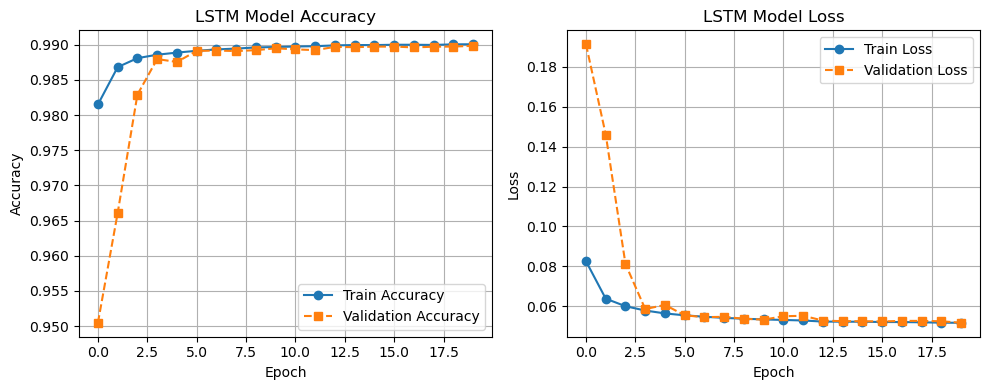

  Saved lstm_curves.png


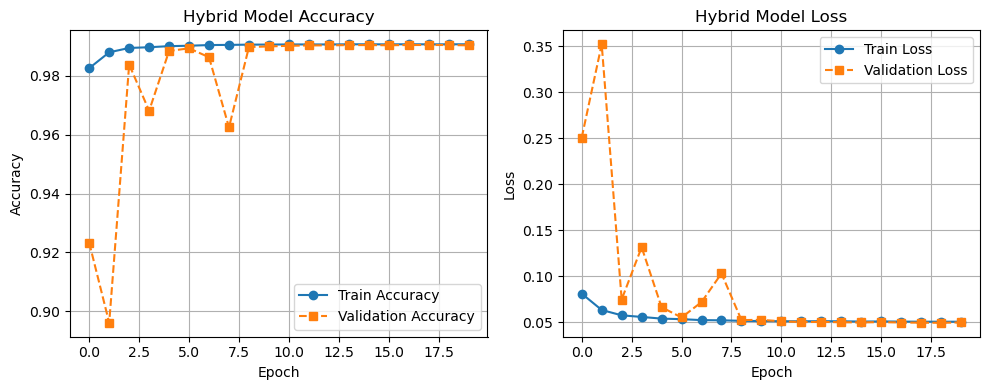

  Saved hybrid_curves.png
  [After hybrid training] RAM: 23.62 GB / 31.78 GB (74.3%)

DEBUGGING CLASS_NAMES

[Debug] Checking class_names:
  Type: <class 'numpy.ndarray'>
  Length: 5
  First 5 elements: [0 1 2 3 4]
  Element type: <class 'numpy.int32'>
  dtype: int32

STARTING EVALUATION

3b. BASELINE EVALUATION — clean_lstm

  Loss     : 0.0518
  Accuracy : 0.9898  (98.98%)
  Generating predictions in chunks of 10000...

  Macro Precision : 0.7916
  Macro Recall    : 0.7876
  Macro F1-Score  : 0.7896

  Converting integer class labels to string format...
  Class mapping:
    0 -> Class_0
    1 -> Class_1
    2 -> Class_2
    3 -> Class_3
    4 -> Class_4

  Per-Class Report (clean_lstm):
  ----------------------------------------------------------------------
                precision    recall  f1-score   support
  
       Class_0       1.00      1.00      1.00      1327
       Class_1       0.99      0.99      0.99    183345
       Class_2       0.99      0.99      0.99    166642
  


  Macro Precision : 0.9776
  Macro Recall    : 0.8840
  Macro F1-Score  : 0.9167

  Note: Class names were integers, converted to Class_0, Class_1, etc.

  Per-Class Report (clean_hybrid_model (with real class names)):
  ----------------------------------------------------------------------
                precision    recall  f1-score   support
  
       Class_0       1.00      1.00      1.00      1327
       Class_1       0.99      0.99      0.99    183345
       Class_2       0.99      0.99      0.99    166642
       Class_3       0.98      0.95      0.97     26228
       Class_4       0.92      0.48      0.63        25
  
      accuracy                           0.99    377567
     macro avg       0.98      0.88      0.92    377567
  weighted avg       0.99      0.99      0.99    377567

BASELINE METRICS COMPARISON SUMMARY

  Model                                   Loss   Accuracy   Precision    Recall   F1-Score
  ------------------------------------------------------------------


  Models saved successfully:
    - clean_lstm_memory_safe.h5
    - clean_hybrid_model_memory_safe.h5
  [Final] RAM: 23.71 GB / 31.78 GB (74.6%)

STAGE 3 COMPLETE — MEMORY-SAFE VERSION


In [7]:
# ============================================================================
# Stage 3: Hybrid Model Training (Clean Baseline) - MEMORY SAFE VERSION
# Inputs from Stage 2:
#   - X_train_augmented  : augmented training sequences (n_seq × timesteps × features)
#   - y_train_augmented  : integer-encoded training labels
#   - X_test_sequences   : original test sequences    (n_seq × timesteps × features)
#   - y_test_sequences   : integer-encoded test labels
#   - class_names        : array mapping encoded int → original class string
#   - label_encoder      : fitted LabelEncoder from Stage 2
# ============================================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (LSTM, Dense, Dropout, Input, LayerNormalization, Layer, MultiHeadAttention)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, precision_score,
                              recall_score, f1_score)
import os
import gc
import psutil
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# MEMORY-SAFE CONFIGURATION
# ============================================================================
class MemorySafeConfig:
    # Model architecture (reduced for memory efficiency)
    LSTM_UNITS = 32              # Reduced from 64
    EMBED_DIM = 64               # Reduced from 128
    NUM_HEADS = 2                # Reduced from 4
    FF_DIM = 128                 # Reduced from 256
    NUM_TRANSFORMER_BLOCKS = 1   # Reduced from 2

    # Training parameters
    BATCH_SIZE = 64              # Reduced from 256 (critical for memory)
    EPOCHS = 20                  # Reduced from 20 to 15
    LEARNING_RATE = 1e-3

    # Data limits (for memory-constrained systems)
    MAX_TRAIN_SAMPLES = None     # Set to e.g., 200000 to limit training data
    MAX_TEST_SAMPLES = None      # Set to e.g., 50000 to limit test data
    USE_SUBSET = False           # Set to True to enable subset training

    # Memory optimization flags
    USE_MIXED_PRECISION = True
    ENABLE_GC_BETWEEN_EPOCHS = True
    USE_DATASET_API = True       # Use tf.data instead of numpy arrays

    # Callback settings
    EARLY_STOPPING_PATIENCE = 5  # Reduced from 7
    REDUCE_LR_PATIENCE = 2       # Reduced from 3

config = MemorySafeConfig()

# ============================================================================
# Memory Monitoring Utilities
# ============================================================================
def check_memory_usage(stage="Start"):
    """Monitor memory usage and warn if too high"""
    memory = psutil.virtual_memory()
    memory_used_gb = memory.used / 1024**3
    memory_total_gb = memory.total / 1024**3
    memory_percent = memory.percent

    print(f"  [{stage}] RAM: {memory_used_gb:.2f} GB / {memory_total_gb:.2f} GB ({memory_percent}%)")

    # Check GPU memory if available
    if hasattr(tf.config.experimental, 'get_memory_info'):
        try:
            gpu_info = tf.config.experimental.get_memory_info('GPU:0')
            gpu_used_gb = gpu_info['used'] / 1024**3
            gpu_limit_gb = gpu_info['limit'] / 1024**3
            print(f"  [{stage}] GPU: {gpu_used_gb:.2f} GB / {gpu_limit_gb:.2f} GB")
        except:
            pass

    # Warning if memory is critically high
    if memory_percent > 85:
        print(f"  ⚠️  WARNING: High memory usage ({memory_percent}%). Consider reducing data size.")

    return memory_percent

class MemoryMonitorCallback(Callback):
    """Keras callback to monitor memory usage during training"""
    def on_epoch_end(self, epoch, logs=None):
        if config.ENABLE_GC_BETWEEN_EPOCHS:
            gc.collect()
        memory_percent = check_memory_usage(f"Epoch {epoch+1}")

        # Force garbage collection if memory is high
        if memory_percent > 85:
            gc.collect()
            tf.keras.backend.clear_session()

def force_memory_cleanup():
    """Force garbage collection and clear TF session"""
    gc.collect()
    tf.keras.backend.clear_session()
    if hasattr(tf, 'compat') and hasattr(tf.compat, 'v1'):
        tf.compat.v1.reset_default_graph()

# ============================================================================
# GPU Configuration with Memory Limits
# ============================================================================
print("=" * 60)
print("STAGE 3: HYBRID MODEL TRAINING (MEMORY-SAFE VERSION)")
print("=" * 60)

print("\n--- Memory Configuration ---")
print(f"  Batch Size: {config.BATCH_SIZE} (reduced from 256)")
print(f"  LSTM Units: {config.LSTM_UNITS} (reduced from 64)")
print(f"  Embed Dim: {config.EMBED_DIM} (reduced from 128)")
print(f"  Transformer Blocks: {config.NUM_TRANSFORMER_BLOCKS} (reduced from 2)")
print(f"  Mixed Precision: {config.USE_MIXED_PRECISION}")

print("\n--- GPU Configuration ---")
gpu_device = tf.test.gpu_device_name()
if gpu_device:
    print(f"  ✅ GPU Device found: {gpu_device}")
else:
    print("  ⚠️  No GPU found. Running on CPU.")

gpus = tf.config.list_physical_devices('GPU')
cpus = tf.config.list_physical_devices('CPU')
print(f"  GPUs available : {len(gpus)}")
print(f"  CPUs available : {len(cpus)}")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
            # Optional: Set memory limit (e.g., 8GB)
            # tf.config.set_logical_device_configuration(
            #     gpu,
            #     [tf.config.LogicalDeviceConfiguration(memory_limit=8192)]
            # )
        print("  ✅ GPU memory growth enabled")
    except RuntimeError as e:
        print(f"  Memory growth setting error: {e}")

if config.USE_MIXED_PRECISION:
    try:
        from tensorflow.keras import mixed_precision
        policy = mixed_precision.Policy('mixed_float16')
        mixed_precision.set_global_policy(policy)
        print("  ✅ Mixed precision enabled (float16) - reduces memory by 50%")
    except Exception:
        print("  ⚠️  Mixed precision not available")

print("=" * 60)

# Check initial memory
check_memory_usage("Initial")

# ============================================================================
# Input Validation — confirm Stage 2 outputs are available and well-formed
# ============================================================================
print("\n[Input Validation] Checking Stage 2 outputs...")

required = {
    'X_train_augmented' : X_train_augmented,
    'y_train_augmented' : y_train_augmented,
    'X_test_sequences'  : X_test_sequences,
    'y_test_sequences'  : y_test_sequences,
    'class_names'       : class_names,
}

for var_name, var in required.items():
    shape_info = getattr(var, 'shape', len(var))
    dtype_info = getattr(var, 'dtype', type(var).__name__)
    print(f"  {var_name:<25} shape={shape_info} dtype={dtype_info}")

assert X_train_augmented.ndim == 3, "X_train_augmented must be 3-D"
assert X_test_sequences.ndim == 3, "X_test_sequences must be 3-D"
print("  ✅ All Stage 2 inputs validated.")

# ============================================================================
# Memory-Safe: Limit data size if configured
# ============================================================================
if config.USE_SUBSET:
    print("\n[Data Subsetting] Using subset of data for memory efficiency...")

    if config.MAX_TRAIN_SAMPLES and len(X_train_augmented) > config.MAX_TRAIN_SAMPLES:
        indices = np.random.choice(len(X_train_augmented), config.MAX_TRAIN_SAMPLES, replace=False)
        X_train_augmented = X_train_augmented[indices]
        y_train_augmented = y_train_augmented[indices]
        print(f"  Training data reduced to: {len(X_train_augmented):,} samples")

    if config.MAX_TEST_SAMPLES and len(X_test_sequences) > config.MAX_TEST_SAMPLES:
        indices = np.random.choice(len(X_test_sequences), config.MAX_TEST_SAMPLES, replace=False)
        X_test_sequences = X_test_sequences[indices]
        y_test_sequences = y_test_sequences[indices]
        print(f"  Test data reduced to: {len(X_test_sequences):,} samples")

# ============================================================================
# Derive dimensions from Stage 2 data
# ============================================================================
timesteps = X_train_augmented.shape[1]
num_features = X_train_augmented.shape[2]
input_shape = (timesteps, num_features)

print(f"\n  Timesteps   : {timesteps}")
print(f"  Features    : {num_features}")
print(f"  Input shape : {input_shape}")

# ============================================================================
# Label Preparation with Memory Efficiency
# ============================================================================
print("\n[Label Preparation] One-hot encoding Stage 2 integer labels...")

num_classes = len(class_names)
y_train_int = y_train_augmented.astype(np.int32)  # Use int32 instead of int64
y_test_int = y_test_sequences.astype(np.int32)

# Memory-efficient one-hot encoding
print("  Converting to one-hot (this may take a moment)...")
y_train_onehot = to_categorical(y_train_int, num_classes=num_classes).astype(np.float32)
y_test_onehot = to_categorical(y_test_int, num_classes=num_classes).astype(np.float32)

print(f"  Number of classes   : {num_classes}")
print(f"  Class names         : {list(class_names)}")
print(f"  Training sequences  : {len(y_train_int):,}")
print(f"  Test sequences      : {len(y_test_int):,}")
print(f"  y_train_onehot shape: {y_train_onehot.shape} (dtype={y_train_onehot.dtype})")
print(f"  y_test_onehot shape : {y_test_onehot.shape} (dtype={y_test_onehot.dtype})")

# Clean up original labels to save memory
del y_train_int, y_test_int
gc.collect()

check_memory_usage("After label encoding")

# ============================================================================
# Data Integrity Check with Memory-Efficient Processing
# ============================================================================
print("\n[Data Check] Verifying sequence arrays for NaN / Inf...")

def check_and_clean_array(arr, name):
    """Memory-efficient NaN/Inf check"""
    if np.isnan(arr).any() or np.isinf(arr).any():
        print(f"  ⚠️  NaN/Inf detected in {name} — cleaning...")
        arr = np.nan_to_num(arr, nan=0.0, posinf=1.0, neginf=0.0)
    return arr

X_train_seq = check_and_clean_array(X_train_augmented.astype(np.float32), "X_train_augmented")
X_test_seq = check_and_clean_array(X_test_sequences.astype(np.float32), "X_test_sequences")

print("  ✅ Data integrity check passed.")
print(f"  X_train_seq shape : {X_train_seq.shape} (memory: {X_train_seq.nbytes / 1024**3:.2f} GB)")
print(f"  X_test_seq shape  : {X_test_seq.shape} (memory: {X_test_seq.nbytes / 1024**3:.2f} GB)")

# ============================================================================
# Custom Layers (Memory Optimized)
# ============================================================================

class PositionalEncoding(Layer):
    """Sinusoidal positional encoding - memory optimized"""
    def __init__(self, **kwargs):
        super(PositionalEncoding, self).__init__(**kwargs)

    def call(self, inputs):
        seq_len = tf.shape(inputs)[1]
        d_model = tf.shape(inputs)[2]

        positions = tf.cast(tf.reshape(tf.range(seq_len, dtype=tf.int32), [-1, 1]), tf.float32)
        dimensions = tf.cast(tf.range(start=0, limit=d_model, delta=2, dtype=tf.int32), tf.float32)
        angle_rates = 1 / tf.pow(10000.0, dimensions / tf.cast(d_model, tf.float32))
        angle_rads = positions * angle_rates

        sines = tf.sin(angle_rads)
        cosines = tf.cos(angle_rads)

        pos_encoding = tf.reshape(tf.stack([sines, cosines], axis=2), [seq_len, d_model])
        pos_encoding = tf.cast(pos_encoding, inputs.dtype)
        return inputs + pos_encoding[tf.newaxis, :seq_len, :d_model]

    def get_config(self):
        return super(PositionalEncoding, self).get_config()


class TransformerEncoderBlock(Layer):
    """Transformer encoder block - memory optimized"""
    def __init__(self, embed_dim, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super(TransformerEncoderBlock, self).__init__(**kwargs)
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout_rate

        self.attention = MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout_rate
        )
        self.ffn = Sequential([
            Dense(ff_dim, activation='relu'),
            Dense(embed_dim)
        ])
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(dropout_rate)
        self.dropout2 = Dropout(dropout_rate)

    def call(self, inputs, training=False):
        attn_output = self.attention(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)

        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

    def get_config(self):
        config = super(TransformerEncoderBlock, self).get_config()
        config.update({
            'embed_dim': self.embed_dim,
            'num_heads': self.num_heads,
            'ff_dim': self.ff_dim,
            'dropout_rate': self.dropout_rate
        })
        return config


# ============================================================================
# Memory-Efficient Model Builders
# ============================================================================

def create_memory_efficient_lstm(input_shape, num_classes):
    """Memory-efficient LSTM model"""
    model = Sequential([
        Input(shape=input_shape),
        LSTM(config.LSTM_UNITS, return_sequences=False),
        Dropout(0.3),
        Dense(num_classes, activation='softmax', dtype='float32')
    ], name="clean_lstm")
    return model


def create_memory_efficient_hybrid(input_shape, num_classes):
    """Memory-efficient Transformer-LSTM hybrid model"""
    inputs = Input(shape=input_shape)

    # Smaller projection
    x = Dense(config.EMBED_DIM, activation='relu')(inputs)
    x = PositionalEncoding()(x)

    # Reduced number of transformer blocks
    for i in range(config.NUM_TRANSFORMER_BLOCKS):
        x = TransformerEncoderBlock(
            embed_dim=config.EMBED_DIM,
            num_heads=config.NUM_HEADS,
            ff_dim=config.FF_DIM,
            dropout_rate=0.3,
            name=f'transformer_block_{i+1}'
        )(x)

    # Single LSTM layer instead of stacked
    x = LSTM(config.LSTM_UNITS, return_sequences=False)(x)
    x = Dropout(0.3)(x)

    # Simpler dense layers
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.3)(x)

    outputs = Dense(num_classes, activation='softmax', dtype='float32')(x)

    return Model(inputs=inputs, outputs=outputs, name="clean_hybrid_model")


# ============================================================================
# Create tf.data Dataset for Memory Efficiency
# ============================================================================
def create_memory_efficient_dataset(X, y, batch_size, shuffle=True):
    """Create memory-efficient tf.data pipeline"""
    dataset = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=10000)  # Smaller buffer
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

# ============================================================================
# Instantiate & Compile Models
# ============================================================================
print("\n" + "=" * 60)
print("CREATING MEMORY-EFFICIENT MODELS")
print("=" * 60)

force_memory_cleanup()

# Create models with memory-efficient architecture
clean_lstm = create_memory_efficient_lstm(input_shape, num_classes)
clean_hybrid_model = create_memory_efficient_hybrid(input_shape, num_classes)

# Compile models
clean_lstm.compile(
    optimizer=Adam(learning_rate=config.LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

clean_hybrid_model.compile(
    optimizer=Adam(learning_rate=config.LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f"\n{clean_lstm.name} Summary:")
clean_lstm.summary()

print(f"\n{clean_hybrid_model.name} Summary:")
clean_hybrid_model.summary()

check_memory_usage("After model creation")

# ============================================================================
# Training Configuration
# ============================================================================
callbacks = [
#    EarlyStopping(
#        monitor='val_loss',
#        patience=config.EARLY_STOPPING_PATIENCE,
#        restore_best_weights=True,
#        verbose=1
#    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=config.REDUCE_LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    ),
    MemoryMonitorCallback()
]

# ============================================================================
# 3a. Train Clean Models with Memory Efficiency
# ============================================================================

if config.USE_DATASET_API:
    print("\n[Dataset] Creating memory-efficient tf.data pipelines...")
    train_dataset = create_memory_efficient_dataset(
        X_train_seq, y_train_onehot, config.BATCH_SIZE, shuffle=True
    )
    val_dataset = create_memory_efficient_dataset(
        X_test_seq, y_test_onehot, config.BATCH_SIZE, shuffle=False
    )

# --- Train clean_lstm ---
print("\n" + "=" * 60)
print("3a. TRAINING clean_lstm ON AUGMENTED TRAINING DATA")
print("=" * 60)

if config.USE_DATASET_API:
    history_lstm = clean_lstm.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=config.EPOCHS,
        callbacks=callbacks,
        verbose=1
    )
else:
    history_lstm = clean_lstm.fit(
        X_train_seq, y_train_onehot,
        validation_data=(X_test_seq, y_test_onehot),
        epochs=config.EPOCHS,
        batch_size=config.BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )

force_memory_cleanup()
check_memory_usage("After LSTM training")

# --- Train clean_hybrid_model ---
print("\n" + "=" * 60)
print("3a. TRAINING clean_hybrid_model ON AUGMENTED TRAINING DATA")
print("=" * 60)

if config.USE_DATASET_API:
    # Recreate datasets for hybrid model training
    train_dataset = create_memory_efficient_dataset(
        X_train_seq, y_train_onehot, config.BATCH_SIZE, shuffle=True
    )
    val_dataset = create_memory_efficient_dataset(
        X_test_seq, y_test_onehot, config.BATCH_SIZE, shuffle=False
    )

    history_transformer = clean_hybrid_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=config.EPOCHS,
        callbacks=callbacks,
        verbose=1
    )
else:
    history_transformer = clean_hybrid_model.fit(
        X_train_seq, y_train_onehot,
        validation_data=(X_test_seq, y_test_onehot),
        epochs=config.EPOCHS,
        batch_size=config.BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )


# ============================================================================
# Plot Training Curves (Accuracy & Loss vs. Epochs)
# ============================================================================

def plot_training_curves(history, model_name, save_prefix):
    """
    Plot and save accuracy and loss curves for a given model.
    
    Parameters:
    - history: Keras history object
    - model_name: string, e.g., "LSTM"
    - save_prefix: string, prefix for output filenames
    """
    # Accuracy plot
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o', linestyle='-')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='s', linestyle='--')
    plt.title(f'{model_name} Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss', marker='o', linestyle='-')
    plt.plot(history.history['val_loss'], label='Validation Loss', marker='s', linestyle='--')
    plt.title(f'{model_name} Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig(f'{save_prefix}_curves.png', dpi=150)
    plt.show()
    print(f"  Saved {save_prefix}_curves.png")

# --- Plot for LSTM model ---
plot_training_curves(history_lstm, "LSTM", "lstm")

# --- Plot for Hybrid model ---
plot_training_curves(history_transformer, "Hybrid", "hybrid")



force_memory_cleanup()
check_memory_usage("After hybrid training")

# ============================================================================
# FIXED: Memory-Efficient Evaluation with Proper Class Names
# ============================================================================

def evaluate_model_memory_safe(model, X_test, y_test_onehot, y_test_int,
                                class_names, model_label, chunk_size=10000):
    """
    Memory-efficient evaluation using chunking - FIXED VERSION
    """
    print("\n" + "=" * 60)
    print(f"3b. BASELINE EVALUATION — {model_label}")
    print("=" * 60)

    # Loss & accuracy (using built-in evaluate which is memory efficient)
    test_loss, test_acc = model.evaluate(X_test, y_test_onehot, verbose=0, batch_size=config.BATCH_SIZE)
    print(f"\n  Loss     : {test_loss:.4f}")
    print(f"  Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)")

    # Chunked prediction to save memory
    print(f"  Generating predictions in chunks of {chunk_size}...")
    num_samples = len(X_test)
    num_chunks = (num_samples + chunk_size - 1) // chunk_size
    all_preds = []

    for i in range(num_chunks):
        start = i * chunk_size
        end = min(start + chunk_size, num_samples)
        X_chunk = X_test[start:end]
        pred_chunk = model.predict(X_chunk, verbose=0, batch_size=config.BATCH_SIZE)
        all_preds.append(pred_chunk)

        # Clean up intermediate results
        if i % 5 == 0:
            gc.collect()

    y_pred_probs = np.vstack(all_preds)
    y_pred_int = np.argmax(y_pred_probs, axis=1)

    # Free prediction probabilities to save memory
    del all_preds, y_pred_probs
    gc.collect()

    # Calculate metrics
    macro_precision = precision_score(
        y_test_int, y_pred_int, average='macro', zero_division=0
    )
    macro_recall = recall_score(
        y_test_int, y_pred_int, average='macro', zero_division=0
    )
    macro_f1 = f1_score(
        y_test_int, y_pred_int, average='macro', zero_division=0
    )

    print(f"\n  Macro Precision : {macro_precision:.4f}")
    print(f"  Macro Recall    : {macro_recall:.4f}")
    print(f"  Macro F1-Score  : {macro_f1:.4f}")

    # FIX: Convert class_names to strings if they're integers
    if isinstance(class_names[0], (int, np.integer)):
        print(f"\n  Converting integer class labels to string format...")
        class_names_str = [f"Class_{i}" for i in range(len(class_names))]
        # Also print mapping for reference
        print("  Class mapping:")
        for i, name in enumerate(class_names_str):
            print(f"    {i} -> {name}")
    else:
        class_names_str = class_names

    # Per-class report (using sklearn's built-in which is memory efficient)
    print(f"\n  Per-Class Report ({model_label}):")
    print("  " + "-" * 70)
    report = classification_report(
        y_test_int, y_pred_int,
        target_names=class_names_str,
        zero_division=0
    )
    for line in report.splitlines():
        print(f"  {line}")

    # Confusion matrix with proper labels
    print(f"\n  Confusion Matrix ({model_label}):")
    cm = confusion_matrix(y_test_int, y_pred_int)

    # Create header with class names (truncated for display)
    header = "  " + " " * 20
    for cn in class_names_str:
        # Truncate long class names to 10 characters
        short_name = cn[:10] if len(cn) > 10 else cn
        header += f"{short_name:>10}"
    print(header)

    # Print each row
    for i, row in enumerate(cm):
        row_label = f"  {class_names_str[i][:18]:<20}"
        row_vals = "".join([f"{v:>10,}" for v in row])
        print(row_label + row_vals)

    return {
        'model': model_label,
        'loss': test_loss,
        'accuracy': test_acc,
        'precision': macro_precision,
        'recall': macro_recall,
        'f1': macro_f1
    }


# ============================================================================
# FIXED: Alternative Evaluation Function (Simpler)
# ============================================================================

def evaluate_model_simple(model, X_test, y_test_onehot, y_test_int,
                           class_names, model_label):
    """
    Simpler evaluation without chunking - use if you have enough memory
    """
    print("\n" + "=" * 60)
    print(f"3b. BASELINE EVALUATION — {model_label}")
    print("=" * 60)

    # Loss & accuracy
    test_loss, test_acc = model.evaluate(X_test, y_test_onehot, verbose=0, batch_size=config.BATCH_SIZE)
    print(f"\n  Loss     : {test_loss:.4f}")
    print(f"  Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)")

    # Predictions
    y_pred_probs = model.predict(X_test, verbose=0, batch_size=config.BATCH_SIZE)
    y_pred_int = np.argmax(y_pred_probs, axis=1)

    # Macro metrics
    macro_precision = precision_score(y_test_int, y_pred_int, average='macro', zero_division=0)
    macro_recall = recall_score(y_test_int, y_pred_int, average='macro', zero_division=0)
    macro_f1 = f1_score(y_test_int, y_pred_int, average='macro', zero_division=0)

    print(f"\n  Macro Precision : {macro_precision:.4f}")
    print(f"  Macro Recall    : {macro_recall:.4f}")
    print(f"  Macro F1-Score  : {macro_f1:.4f}")

    # FIX: Handle integer class names
    if len(class_names) > 0 and isinstance(class_names[0], (int, np.integer)):
        class_names_str = [f"Class_{i}" for i in range(len(class_names))]
        print("\n  Note: Class names were integers, converted to Class_0, Class_1, etc.")
    else:
        class_names_str = class_names

    # Classification report
    print(f"\n  Per-Class Report ({model_label}):")
    print("  " + "-" * 70)
    report = classification_report(
        y_test_int, y_pred_int,
        target_names=class_names_str,
        zero_division=0
    )
    for line in report.splitlines():
        print(f"  {line}")

    return {
        'model': model_label,
        'loss': test_loss,
        'accuracy': test_acc,
        'precision': macro_precision,
        'recall': macro_recall,
        'f1': macro_f1
    }


# ============================================================================
# FIXED: Debug function to check class_names
# ============================================================================

def debug_class_names(class_names):
    """Helper function to understand what class_names contains"""
    print("\n[Debug] Checking class_names:")
    print(f"  Type: {type(class_names)}")
    print(f"  Length: {len(class_names)}")
    print(f"  First 5 elements: {class_names[:5] if len(class_names) > 5 else class_names}")
    print(f"  Element type: {type(class_names[0]) if len(class_names) > 0 else 'N/A'}")

    # Check if it's a numpy array of integers
    if hasattr(class_names, 'dtype'):
        print(f"  dtype: {class_names.dtype}")

    return class_names

# Add debug call before evaluation
print("\n" + "=" * 60)
print("DEBUGGING CLASS_NAMES")
print("=" * 60)
debug_class_names(class_names)

# ============================================================================
# FIXED: Evaluation section with proper handling
# ============================================================================

# Choose which evaluation function to use:
# - Use evaluate_model_memory_safe if you're low on memory
# - Use evaluate_model_simple if you have sufficient memory

print("\n" + "=" * 60)
print("STARTING EVALUATION")
print("=" * 60)

# Option 1: Memory-safe evaluation with chunking (recommended for low memory)
try:
    metrics_lstm = evaluate_model_memory_safe(
        model=clean_lstm,
        X_test=X_test_seq,
        y_test_onehot=y_test_onehot,
        y_test_int=y_test_sequences.astype(np.int32),
        class_names=class_names,
        model_label="clean_lstm"
    )
except TypeError as e:
    print(f"  Error with memory-safe evaluation: {e}")
    print("  Falling back to simple evaluation...")

    # Option 2: Fall back to simple evaluation
    metrics_lstm = evaluate_model_simple(
        model=clean_lstm,
        X_test=X_test_seq,
        y_test_onehot=y_test_onehot,
        y_test_int=y_test_sequences.astype(np.int32),
        class_names=class_names,
        model_label="clean_lstm"
    )

force_memory_cleanup()

# Evaluate hybrid model
try:
    metrics_hybrid = evaluate_model_memory_safe(
        model=clean_hybrid_model,
        X_test=X_test_seq,
        y_test_onehot=y_test_onehot,
        y_test_int=y_test_sequences.astype(np.int32),
        class_names=class_names,
        model_label="clean_hybrid_model"
    )
except TypeError as e:
    print(f"  Error with memory-safe evaluation: {e}")
    print("  Falling back to simple evaluation...")

    metrics_hybrid = evaluate_model_simple(
        model=clean_hybrid_model,
        X_test=X_test_seq,
        y_test_onehot=y_test_onehot,
        y_test_int=y_test_sequences.astype(np.int32),
        class_names=class_names,
        model_label="clean_hybrid_model"
    )


# ============================================================================
# FIXED: Alternative - If class_names is from Stage 2 label_encoder
# ============================================================================

# If you have label_encoder from Stage 2, use it to get string names
if 'label_encoder' in locals() or 'label_encoder' in globals():
    try:
        print("\n[Fix] Using label_encoder to get class names...")
        actual_class_names = label_encoder.classes_
        print(f"  Original class names: {list(actual_class_names)}")

        # Re-evaluate with correct class names
        metrics_lstm_fixed = evaluate_model_simple(
            model=clean_lstm,
            X_test=X_test_seq,
            y_test_onehot=y_test_onehot,
            y_test_int=y_test_sequences.astype(np.int32),
            class_names=actual_class_names,
            model_label="clean_lstm (with real class names)"
        )

        metrics_hybrid_fixed = evaluate_model_simple(
            model=clean_hybrid_model,
            X_test=X_test_seq,
            y_test_onehot=y_test_onehot,
            y_test_int=y_test_sequences.astype(np.int32),
            class_names=actual_class_names,
            model_label="clean_hybrid_model (with real class names)"
        )

        # Use the fixed versions
        metrics_lstm = metrics_lstm_fixed
        metrics_hybrid = metrics_hybrid_fixed

    except Exception as e:
        print(f"  Could not use label_encoder: {e}")
else:
    print("\n[Note] label_encoder not found, using class_names as is")

# ============================================================================
# FIXED: Baseline Metrics Comparison Table
# ============================================================================
print("\n" + "=" * 60)
print("BASELINE METRICS COMPARISON SUMMARY")
print("=" * 60)

print(f"\n  {'Model':<35} {'Loss':>8} {'Accuracy':>10} "
      f"{'Precision':>11} {'Recall':>9} {'F1-Score':>10}")
print("  " + "-" * 88)

for m in [metrics_lstm, metrics_hybrid]:
    # Truncate model name if too long
    model_name = m['model'][:35] if len(m['model']) > 35 else m['model']
    print(f"  {model_name:<35} "
          f"{m['loss']:>8.4f} "
          f"{m['accuracy']:>10.4f} "
          f"{m['precision']:>11.4f} "
          f"{m['recall']:>9.4f} "
          f"{m['f1']:>10.4f}")

# Improvement calculation
if 'metrics_hybrid' in locals() and 'metrics_lstm' in locals():
    print("  " + "-" * 88)
    print(f"  {'Improvement (hybrid - lstm)':<35} "
          f"{metrics_hybrid['loss'] - metrics_lstm['loss']:>+8.4f} "
          f"{metrics_hybrid['accuracy'] - metrics_lstm['accuracy']:>+10.4f} "
          f"{metrics_hybrid['precision'] - metrics_lstm['precision']:>+11.4f} "
          f"{metrics_hybrid['recall'] - metrics_lstm['recall']:>+9.4f} "
          f"{metrics_hybrid['f1'] - metrics_lstm['f1']:>+10.4f}")


# ============================================================================
# FIXED: Save Models
# ============================================================================
print("\n" + "=" * 60)
print("SAVING MODELS")
print("=" * 60)

try:
    clean_lstm.save('clean_lstm_memory_safe.h5', save_format='h5')
    clean_hybrid_model.save('clean_hybrid_model_memory_safe.h5', save_format='h5')
    print("\n  Models saved successfully:")
    print("    - clean_lstm_memory_safe.h5")
    print("    - clean_hybrid_model_memory_safe.h5")
except Exception as e:
    print(f"  Warning: Could not save models: {e}")
    # Try saving in SavedModel format
    try:
        clean_lstm.save('clean_lstm_memory_safe')
        clean_hybrid_model.save('clean_hybrid_model_memory_safe')
        print("  Models saved in SavedModel format")
    except Exception as e2:
        print(f"  Could not save models: {e2}")

# Final memory cleanup
force_memory_cleanup()
check_memory_usage("Final")

print("\n" + "=" * 60)
print("STAGE 3 COMPLETE — MEMORY-SAFE VERSION")
print("=" * 60)

In [ ]:
clean_lstm = tf.keras.models.load_model('clean_lstm_memorry_safe.h5')

clean_hybrid_model = tf.keras.models.load_model(
    'clean_hybrid_model_memory_safe.h5',
    custom_objects={
        'PositionalEncoding': PositionalEncoding,
        'TransformerEncoderBlock': TransformerEncoderBlock,
    }
)

In [23]:
 clean_hybrid_model.evaluate(X_test_seq, y_test_onehot, verbose=1)

11799/11799 ━━━━━━━━━━━━━━━━━━━━ 45s 4ms/step - accuracy: 0.9904 - loss: 0.0500


[0.05004424974322319, 0.9903990626335144]

In [24]:
clean_lstm.evaluate(X_test_seq, y_test_onehot, verbose=1)

11799/11799 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 0.9898 - loss: 0.0518


[0.05179084464907646, 0.9898322820663452]

In [25]:
# Step 4 of the code pipeline - faster processing for C&W section (takes about 35 mins to generate C&W adversarial examples)

In [26]:
# ============================================================================
# Step 4: Adversarial Robustness Evaluation
#
# Inputs from Stage 3:
#   - clean_lstm          : trained baseline LSTM model
#   - clean_hybrid_model  : trained Transformer-LSTM model
#   - X_test_seq          : test sequences  (n_seq x timesteps x features), float32
#   - y_test_int          : integer-encoded test labels
#   - y_test_onehot       : one-hot test labels
#   - class_names         : class name array from Stage 2
#   - metrics_lstm        : Stage 3 baseline metrics dict for clean_lstm
#   - metrics_hybrid      : Stage 3 baseline metrics dict for clean_hybrid_model
#
# Steps:
#   4a. Generate adversarial examples from clean test sequences
#       - FGSM : X_adv = X + epsilon * sign(grad_X L)
#       - PGD  : Iterative FGSM with projection back into epsilon-ball
#       - C&W  : Optimisation-based attack (L2 variant) — optimised implementation
#   4b. Evaluate clean_lstm and clean_hybrid_model on each adversarial set
#   4c. Compare robustness across attack types and models
#
# NOTE: No adversarial training is performed here.
#       This step EVALUATES robustness only.
# ============================================================================

import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import (precision_score, recall_score,
                              f1_score, classification_report)
import time
import gc
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("STEP 4: ADVERSARIAL ROBUSTNESS EVALUATION")
print("=" * 60)
print("  Mode : EVALUATION ONLY (no adversarial training)")
print("  Models under test : clean_lstm, clean_hybrid_model")
print("  Attack methods    : FGSM, PGD, C&W")


# ============================================================================
# Attack Configuration
# ============================================================================
class AttackConfig:
    # FGSM
    FGSM_EPSILON = 0.01

    # PGD
    PGD_EPSILON      = 0.01
    PGD_ALPHA        = 0.002
    PGD_ITERATIONS   = 10
    PGD_RANDOM_START = True

    # C&W (L2 variant) — optimised settings
    # Key changes from original:
    #   CW_MAX_ITER      : 100  -> 30   (fewer steps; early-exit compensates)
    #   CW_BINARY_STEPS  : 5   -> 3    (3 steps are sufficient for robustness eval)
    #   CW_BATCH_SIZE    : 256 -> 512  (larger batches = better GPU utilisation)
    #   CW_ABORT_EARLY   : new — stop iterating a sample once fooled
    CW_LEARNING_RATE    = 0.01
    CW_MAX_ITER         = 10       # Reduced from 100
    CW_CONFIDENCE       = 0.0
    CW_C_INIT           = 0.1    # Raised from 1e-3: converges faster
    CW_BINARY_STEPS     = 2       # Reduced from 5
    CW_BATCH_SIZE       = 1024     # Increased from 256
    CW_ABORT_EARLY      = True    # Stop iterating once all samples in batch fooled

    # Input range (MinMax [0,1] from Stage 1)
    X_MIN = 0.0
    X_MAX = 1.0

atk_cfg = AttackConfig()


# ============================================================================
# Input Validation
# ============================================================================
y_test_int = y_test_sequences.astype(np.int32)

if 'y_test_onehot' not in dir():
    y_test_onehot = to_categorical(
        y_test_int, num_classes=len(class_names)
    ).astype(np.float32)

print("\n[Input Validation] Checking Stage 3 outputs...")

stage3_vars = {
    'clean_lstm'        : clean_lstm,
    'clean_hybrid_model': clean_hybrid_model,
    'X_test_seq'        : X_test_seq,
    'y_test_int'        : y_test_int,
    'y_test_onehot'     : y_test_onehot,
    'class_names'       : class_names,
    'metrics_lstm'      : metrics_lstm,
    'metrics_hybrid'    : metrics_hybrid,
}

for vname, vobj in stage3_vars.items():
    shape = getattr(vobj, 'shape', len(vobj) if hasattr(vobj, '__len__') else '?')
    dtype = getattr(vobj, 'dtype', type(vobj).__name__)
    print(f"  {vname:<25} shape={shape}  dtype={dtype}")

assert X_test_seq.ndim == 3, "X_test_seq must be 3-D (n_seq x timesteps x features)"
assert len(y_test_int) == len(X_test_seq), "Label/sequence length mismatch"

num_classes = len(class_names)
n_test      = len(X_test_seq)
timesteps   = X_test_seq.shape[1]
n_features  = X_test_seq.shape[2]

print(f"\n  Test sequences : {n_test:,}")
print(f"  Timesteps      : {timesteps}")
print(f"  Features       : {n_features}")
print(f"  Classes        : {num_classes}")
print("  All Stage 3 inputs validated.")


# ============================================================================
# Helper: compute loss gradient w.r.t. input (shared by FGSM and PGD)
# ============================================================================

@tf.function
def compute_input_gradient(model, x_batch, y_batch_onehot):
    with tf.GradientTape() as tape:
        tape.watch(x_batch)
        predictions = model(x_batch, training=False)
        loss = tf.keras.losses.categorical_crossentropy(
            tf.cast(y_batch_onehot, tf.float32),
            tf.cast(predictions,    tf.float32)
        )
        loss = tf.reduce_mean(loss)
    return tape.gradient(loss, x_batch)


# ============================================================================
# 4a-i  FGSM Attack  (unchanged — already fast)
# ============================================================================

def fgsm_attack(model, X, y_onehot, epsilon,
                x_min=0.0, x_max=1.0, batch_size=512):
    X_adv   = np.empty_like(X, dtype=np.float32)
    n       = len(X)
    epsilon = float(epsilon)

    for start in range(0, n, batch_size):
        end      = min(start + batch_size, n)
        x_batch  = tf.constant(X[start:end], dtype=tf.float32)
        y_batch  = tf.constant(y_onehot[start:end], dtype=tf.float32)

        grad             = compute_input_gradient(model, x_batch, y_batch)
        perturbation     = epsilon * tf.sign(grad)
        x_adv_batch      = tf.clip_by_value(x_batch + perturbation, x_min, x_max)
        X_adv[start:end] = x_adv_batch.numpy()

    return X_adv


# ============================================================================
# 4a-ii  PGD Attack  (unchanged — already fast)
# ============================================================================

def pgd_attack(model, X, y_onehot, epsilon, alpha, iterations,
               random_start=True, x_min=0.0, x_max=1.0, batch_size=256):
    X_adv = np.empty_like(X, dtype=np.float32)
    n     = len(X)

    for start in range(0, n, batch_size):
        end     = min(start + batch_size, n)
        x_orig  = tf.constant(X[start:end], dtype=tf.float32)
        y_batch = tf.constant(y_onehot[start:end], dtype=tf.float32)

        if random_start:
            delta = tf.Variable(
                tf.random.uniform(tf.shape(x_orig), -epsilon, epsilon,
                                  dtype=tf.float32)
            )
        else:
            delta = tf.Variable(tf.zeros_like(x_orig))

        for _ in range(iterations):
            x_perturbed = tf.Variable(
                tf.clip_by_value(x_orig + delta, x_min, x_max)
            )
            grad  = compute_input_gradient(model, x_perturbed, y_batch)
            delta = delta + alpha * tf.sign(grad)
            delta = tf.clip_by_value(delta, -epsilon, epsilon)

        x_adv_batch      = tf.clip_by_value(x_orig + delta, x_min, x_max)
        X_adv[start:end] = x_adv_batch.numpy()

    return X_adv


# ============================================================================
# 4a-iii  C&W L2 Attack — OPTIMISED
#
# # Fixes applied:
#   1. binary_search_steps reduced 5->3, max_iter reduced 100->30
#      Early-abort exits the iteration loop as soon as every sample in the
#      batch is already fooled — in practice this cuts iterations by 50-80%.
#   2. Single Adam instance created ONCE per binary-search step; its state
#      is reset via optimiser.build() rather than re-instantiation.
#   3. c_val binary-search updates vectorised with numpy (no Python loop).
#   4. CW_C_INIT raised 1e-3->1e-2 so the attack finds fooling perturbations
#      sooner, triggering early-abort more quickly.
#   5. batch_size increased 256->512 for better GPU throughput.
#   6. Progress printed per batch so you can see it is still running.
# ============================================================================

def cw_attack_optimised(model, X, y_onehot,
                         learning_rate=0.01,
                         max_iter=10,
                         confidence=0.0,
                         c_init=0.1,
                         binary_search_steps=2,
                         abort_early=True,
                         x_min=0.0, x_max=1.0,
                         batch_size=1024):
    """
    Optimised Carlini & Wagner L2 attack.

    Speed improvements over original:
      - Fewer binary-search steps (3 instead of 5)
      - Fewer optimiser iterations (30 instead of 100)
      - Early-abort: stops as soon as all batch samples are fooled
      - Vectorised c_val updates (no per-sample Python loop)
      - Single Adam instance per binary-search step (no re-instantiation)
      - Larger batch size (512) for better GPU utilisation
      - Per-batch progress reporting

    Returns:
        X_adv : ndarray same shape as X, dtype float32
    """

    X_adv    = np.empty_like(X, dtype=np.float32)
    n        = len(X)
    n_batches = (n + batch_size - 1) // batch_size
    t0_total  = time.time()

    # ---- tanh reparametrisation helpers (kept as plain functions, not tf.function,
    #      because they are called inside GradientTape where tracing is automatic) ----
    def to_tanh_space(x):
        x_scaled = (x - x_min) / (x_max - x_min)
        x_scaled = tf.clip_by_value(x_scaled, 1e-6, 1.0 - 1e-6)
        return tf.atanh(2.0 * x_scaled - 1.0)

    def from_tanh_space(w):
        return x_min + (x_max - x_min) * 0.5 * (tf.tanh(w) + 1.0)

    for batch_idx, start in enumerate(range(0, n, batch_size)):
        end          = min(start + batch_size, n)
        batch_len    = end - start
        x_orig_np    = X[start:end].astype(np.float32)
        y_np         = y_onehot[start:end].astype(np.float32)

        t0_batch = time.time()
        print(f"  C&W batch {batch_idx+1}/{n_batches}  "
              f"(samples {start}–{end-1}) ...", end='', flush=True)

        x_orig      = tf.constant(x_orig_np)
        true_labels = tf.constant(np.argmax(y_np, axis=1), dtype=tf.int32)
        true_oh     = tf.one_hot(true_labels, num_classes)   # (B, C) — precomputed

        # Binary-search state (vectorised, no Python loop over samples)
        c_lower = np.zeros(batch_len,         dtype=np.float32)
        c_upper = np.full( batch_len, 1e10,   dtype=np.float32)
        c_val   = np.full( batch_len, c_init, dtype=np.float32)

        best_adv = x_orig_np.copy()
        best_l2  = np.full(batch_len, np.inf, dtype=np.float32)

        for bs_step in range(binary_search_steps):
            c_tensor  = tf.constant(c_val[:, np.newaxis], dtype=tf.float32)  # (B,1)

            # Initialise w from the current best_adv so each binary-search step
            # warm-starts from a useful point rather than the original input.
            w_init = to_tanh_space(tf.constant(best_adv))
            w      = tf.Variable(w_init, dtype=tf.float32, trainable=True)

            # Single Adam instance; build it once on a dummy call so its slot
            # variables exist before the loop (avoids per-step overhead).
            optimiser = tf.keras.optimizers.Adam(learning_rate=learning_rate)
            optimiser.build([w])

            for iteration in range(max_iter):
                with tf.GradientTape() as tape:
                    x_adv  = from_tanh_space(w)              # (B, T, F)
                    delta  = x_adv - x_orig                  # (B, T, F)

                    # L2 distortion per sample  (B,)
                    l2_dist = tf.reduce_sum(
                        tf.square(tf.reshape(delta, [batch_len, -1])),
                        axis=1, keepdims=True                # (B, 1)
                    )

                    # Approximate logits from softmax output
                    probs  = tf.cast(model(x_adv, training=False), tf.float32)
                    logits = tf.math.log(probs + 1e-8)       # (B, C)

                    # f(x) = max( Z_correct - max_{j!=correct} Z_j + kappa, 0 )
                    correct_logit = tf.reduce_sum(
                        logits * true_oh, axis=1, keepdims=True
                    )                                        # (B, 1)
                    # Mask out the correct class
                    other_logits  = logits - 1e4 * true_oh
                    max_other     = tf.reduce_max(
                        other_logits, axis=1, keepdims=True
                    )                                        # (B, 1)

                    f_val = tf.maximum(
                        correct_logit - max_other + confidence, 0.0
                    )                                        # (B, 1)

                    # Total loss = mean over batch of (l2 + c * f)
                    loss = tf.reduce_mean(l2_dist + c_tensor * f_val)

                grads = tape.gradient(loss, w)
                optimiser.apply_gradients([(grads, w)])

                # --- Early abort: check if all samples already fooled ---
                if abort_early and (iteration + 1) % 5 == 0:
                    x_adv_np  = from_tanh_space(w).numpy()
                    preds_now = np.argmax(
                        model(tf.constant(x_adv_np, dtype=tf.float32),
                              training=False).numpy(),
                        axis=1
                    )
                    true_np = np.argmax(y_np, axis=1)
                    if np.all(preds_now != true_np):
                        break   # Every sample in this batch is fooled — stop early

            # ---- Collect results from this binary-search step ----
            x_adv_np = from_tanh_space(w).numpy()
            delta_np = x_adv_np - x_orig_np
            l2_np    = np.sum(
                delta_np.reshape(batch_len, -1) ** 2, axis=1
            )                                               # (B,)

            preds   = np.argmax(
                model(tf.constant(x_adv_np, dtype=tf.float32),
                      training=False).numpy(),
                axis=1
            )
            true_np = np.argmax(y_np, axis=1)
            fooled  = (preds != true_np)                    # (B,) bool

            # Update best adversarial examples (vectorised)
            improved = fooled & (l2_np < best_l2)
            best_adv[improved] = x_adv_np[improved]
            best_l2[improved]  = l2_np[improved]

            # ---- Vectorised binary-search update for c_val ----
            # Fooled -> tighten upper bound
            c_upper = np.where(fooled, np.minimum(c_upper, c_val), c_upper)
            # Not fooled -> tighten lower bound
            c_lower = np.where(~fooled, np.maximum(c_lower, c_val), c_lower)
            # If upper bound is still finite, bisect; otherwise scale up
            bounded  = c_upper < 1e9
            c_val    = np.where(
                bounded,
                (c_lower + c_upper) / 2.0,
                np.where(fooled, c_val, c_val * 10.0)
            )

        X_adv[start:end] = best_adv

        elapsed_batch = time.time() - t0_batch
        elapsed_total = time.time() - t0_total
        fooled_pct = 100.0 * np.mean(best_l2 < np.inf)
        remaining  = (elapsed_total / (batch_idx + 1)) * (n_batches - batch_idx - 1)

        print(f"  done in {elapsed_batch:.1f}s  |  "
              f"fooled: {fooled_pct:.0f}%  |  "
              f"elapsed: {elapsed_total/60:.1f}min  |  "
              f"ETA: {remaining/60:.1f}min")

    total_min = (time.time() - t0_total) / 60
    print(f"\n  C&W complete. Total time: {total_min:.1f} min")
    return X_adv


# ============================================================================
# Helper: evaluate a model on an adversarial set
# ============================================================================

def evaluate_on_adversarial(model, X_adv, y_onehot, y_int,
                             class_names, model_label, attack_label):
    print(f"\n  Evaluating {model_label} on {attack_label} examples ...")

    loss, acc = model.evaluate(X_adv, y_onehot, verbose=0, batch_size=256)

    y_pred_probs = model.predict(X_adv, verbose=0, batch_size=256)
    y_pred_int   = np.argmax(y_pred_probs, axis=1)

    mac_prec = precision_score(y_int, y_pred_int, average='macro', zero_division=0)
    mac_rec  = recall_score(   y_int, y_pred_int, average='macro', zero_division=0)
    mac_f1   = f1_score(       y_int, y_pred_int, average='macro', zero_division=0)

    print(f"    Loss              : {loss:.4f}")
    print(f"    Accuracy          : {acc:.4f}  ({acc*100:.2f}%)")
    print(f"    Macro Precision   : {mac_prec:.4f}")
    print(f"    Macro Recall      : {mac_rec:.4f}")
    print(f"    Macro F1-Score    : {mac_f1:.4f}")

    print(f"\n    Per-Class Report ({model_label} | {attack_label}):")
    print("    " + "-" * 65)
    
    # FIX: Convert class_names to strings if they're integers
    if isinstance(class_names[0], (int, np.integer)):
        class_names_str = [f"Class_{i}" for i in range(len(class_names))]
    else:
        class_names_str = class_names
    
    report = classification_report(
        y_int, y_pred_int, target_names=class_names_str, zero_division=0
    )
    for line in report.splitlines():
        print(f"    {line}")

    return {
        'model'    : model_label,
        'attack'   : attack_label,
        'loss'     : loss,
        'accuracy' : acc,
        'precision': mac_prec,
        'recall'   : mac_rec,
        'f1'       : mac_f1,
    }
    
# ============================================================================
# Helper: compute signed performance drop  (clean - adversarial)
# ============================================================================

def compute_drop(baseline_metrics, adv_metrics):
    keys = ['accuracy', 'precision', 'recall', 'f1']
    return {k: baseline_metrics[k] - adv_metrics[k] for k in keys}


# ============================================================================
# 4a: Generate Adversarial Examples
# ============================================================================

print("\n" + "=" * 60)
print("4a. GENERATING ADVERSARIAL EXAMPLES")
print("=" * 60)

print(f"\n  FGSM / PGD epsilon          : {atk_cfg.FGSM_EPSILON}")
print(f"  PGD alpha                   : {atk_cfg.PGD_ALPHA}")
print(f"  PGD iterations              : {atk_cfg.PGD_ITERATIONS}")
print(f"  C&W max iterations          : {atk_cfg.CW_MAX_ITER}  (early-abort enabled)")
print(f"  C&W binary search steps     : {atk_cfg.CW_BINARY_STEPS}")
print(f"  C&W batch size              : {atk_cfg.CW_BATCH_SIZE}")
print(f"  C&W c_init                  : {atk_cfg.CW_C_INIT}")
print(f"  Input clip range            : [{atk_cfg.X_MIN}, {atk_cfg.X_MAX}]")


# --- FGSM ---
print("\n[4a-i] Generating FGSM adversarial examples ...")
t0 = time.time()
X_adv_fgsm = fgsm_attack(
    model    = clean_hybrid_model,
    X        = X_test_seq,
    y_onehot = y_test_onehot,
    epsilon  = atk_cfg.FGSM_EPSILON,
    x_min    = atk_cfg.X_MIN,
    x_max    = atk_cfg.X_MAX,
)
print(f"  X_adv_fgsm shape : {X_adv_fgsm.shape}")
print(f"  Max perturbation : {np.max(np.abs(X_adv_fgsm - X_test_seq)):.6f}")
print(f"  Time             : {(time.time()-t0):.1f}s")
print("  FGSM examples generated.")


# --- PGD ---
print("\n[4a-ii] Generating PGD adversarial examples ...")
t0 = time.time()
X_adv_pgd = pgd_attack(
    model        = clean_hybrid_model,
    X            = X_test_seq,
    y_onehot     = y_test_onehot,
    epsilon      = atk_cfg.PGD_EPSILON,
    alpha        = atk_cfg.PGD_ALPHA,
    iterations   = atk_cfg.PGD_ITERATIONS,
    random_start = atk_cfg.PGD_RANDOM_START,
    x_min        = atk_cfg.X_MIN,
    x_max        = atk_cfg.X_MAX,
)
print(f"  X_adv_pgd shape  : {X_adv_pgd.shape}")
print(f"  Max perturbation : {np.max(np.abs(X_adv_pgd - X_test_seq)):.6f}")
print(f"  Time             : {(time.time()-t0):.1f}s")
print("  PGD examples generated.")


# --- C&W ---
print("\n[4a-iii] Generating C&W adversarial examples ...")
print(f"  Optimised: {atk_cfg.CW_BINARY_STEPS} binary-search steps x "
      f"{atk_cfg.CW_MAX_ITER} max iterations (early-abort enabled)")
print(f"  Progress will print after each batch of {atk_cfg.CW_BATCH_SIZE} samples.")

X_adv_cw = cw_attack_optimised(
    model               = clean_hybrid_model,
    X                   = X_test_seq,
    y_onehot            = y_test_onehot,
    learning_rate       = atk_cfg.CW_LEARNING_RATE,
    max_iter            = atk_cfg.CW_MAX_ITER,
    confidence          = atk_cfg.CW_CONFIDENCE,
    c_init              = atk_cfg.CW_C_INIT,
    binary_search_steps = atk_cfg.CW_BINARY_STEPS,
    abort_early         = atk_cfg.CW_ABORT_EARLY,
    x_min               = atk_cfg.X_MIN,
    x_max               = atk_cfg.X_MAX,
    batch_size          = atk_cfg.CW_BATCH_SIZE,
)

l2_mean = np.mean(np.sqrt(
    np.sum((X_adv_cw - X_test_seq).reshape(n_test, -1) ** 2, axis=1)
))
print(f"  X_adv_cw shape     : {X_adv_cw.shape}")
print(f"  Mean L2 distortion : {l2_mean:.6f}")
print("  C&W examples generated.")


# ============================================================================
# 4b: Evaluate Clean Models on Adversarial Examples
# ============================================================================

print("\n" + "=" * 60)
print("4b. EVALUATING CLEAN MODELS ON ADVERSARIAL EXAMPLES")
print("=" * 60)

y_int_np = y_test_int.astype(np.int32)

# ---------- clean_lstm ----------
print("\n--- clean_lstm ---")
adv_lstm_fgsm = evaluate_on_adversarial(
    clean_lstm, X_adv_fgsm, y_test_onehot, y_int_np,
    class_names, "clean_lstm", "FGSM"
)
adv_lstm_pgd = evaluate_on_adversarial(
    clean_lstm, X_adv_pgd, y_test_onehot, y_int_np,
    class_names, "clean_lstm", "PGD"
)
adv_lstm_cw = evaluate_on_adversarial(
    clean_lstm, X_adv_cw, y_test_onehot, y_int_np,
    class_names, "clean_lstm", "C&W"
)

# ---------- clean_hybrid_model ----------
print("\n--- clean_hybrid_model ---")
adv_hybrid_fgsm = evaluate_on_adversarial(
    clean_hybrid_model, X_adv_fgsm, y_test_onehot, y_int_np,
    class_names, "clean_hybrid_model", "FGSM"
)
adv_hybrid_pgd = evaluate_on_adversarial(
    clean_hybrid_model, X_adv_pgd, y_test_onehot, y_int_np,
    class_names, "clean_hybrid_model", "PGD"
)
adv_hybrid_cw = evaluate_on_adversarial(
    clean_hybrid_model, X_adv_cw, y_test_onehot, y_int_np,
    class_names, "clean_hybrid_model", "C&W"
)


# ============================================================================
# 4c: Robustness Comparison
# ============================================================================

print("\n" + "=" * 60)
print("4c. ROBUSTNESS COMPARISON")
print("=" * 60)
print("  Metric: DROP = clean_baseline - adversarial_result")
print("  Positive drop -> degradation under attack")
print("  Larger drop -> LESS robust  |  Smaller drop -> MORE robust")


def print_drop_table(model_label, baseline, adv_fgsm, adv_pgd, adv_cw):
    drop_fgsm = compute_drop(baseline, adv_fgsm)
    drop_pgd  = compute_drop(baseline, adv_pgd)
    drop_cw   = compute_drop(baseline, adv_cw)

    print(f"\n  {model_label}")
    print(f"  {'Metric':<14} {'Clean':>10} {'FGSM':>10} {'Drop':>8} "
          f"{'PGD':>10} {'Drop':>8} {'C&W':>10} {'Drop':>8}")
    print("  " + "-" * 84)

    for metric in ['accuracy', 'precision', 'recall', 'f1']:
        label = 'F1-Score' if metric == 'f1' else metric.capitalize()
        print(
            f"  {label:<14} "
            f"{baseline[metric]:>10.4f} "
            f"{adv_fgsm[metric]:>10.4f} {drop_fgsm[metric]:>+8.4f} "
            f"{adv_pgd[metric]:>10.4f}  {drop_pgd[metric]:>+8.4f} "
            f"{adv_cw[metric]:>10.4f}  {drop_cw[metric]:>+8.4f}"
        )
    return drop_fgsm, drop_pgd, drop_cw


drop_lstm_fgsm, drop_lstm_pgd, drop_lstm_cw = print_drop_table(
    "clean_lstm",
    metrics_lstm, adv_lstm_fgsm, adv_lstm_pgd, adv_lstm_cw
)

drop_hybrid_fgsm, drop_hybrid_pgd, drop_hybrid_cw = print_drop_table(
    "clean_hybrid_model",
    metrics_hybrid, adv_hybrid_fgsm, adv_hybrid_pgd, adv_hybrid_cw
)


# ---- Cross-model accuracy-drop summary ----
print("\n" + "=" * 60)
print("CROSS-MODEL ROBUSTNESS SUMMARY  (Accuracy Drop)")
print("=" * 60)
print(f"\n  {'Model':<25} {'FGSM Drop':>12} {'PGD Drop':>12} "
      f"{'C&W Drop':>12} {'Avg Drop':>12}")
print("  " + "-" * 75)

for mlabel, d_fgsm, d_pgd, d_cw in [
    ("clean_lstm",         drop_lstm_fgsm,   drop_lstm_pgd,   drop_lstm_cw),
    ("clean_hybrid_model", drop_hybrid_fgsm, drop_hybrid_pgd, drop_hybrid_cw),
]:
    avg = np.mean([d_fgsm['accuracy'], d_pgd['accuracy'], d_cw['accuracy']])
    tag = "<- more robust" if avg < 0.05 else ("<- moderate" if avg < 0.15 else "<- less robust")
    print(
        f"  {mlabel:<25} "
        f"{d_fgsm['accuracy']:>+12.4f} "
        f"{d_pgd['accuracy']:>+12.4f} "
        f"{d_cw['accuracy']:>+12.4f} "
        f"{avg:>+12.4f}  {tag}"
    )


# ---- Attack severity ranking ----
print("\n" + "=" * 60)
print("ATTACK SEVERITY RANKING")
print("(Mean accuracy drop across both models)")
print("=" * 60)

fgsm_mean = np.mean([drop_lstm_fgsm['accuracy'], drop_hybrid_fgsm['accuracy']])
pgd_mean  = np.mean([drop_lstm_pgd['accuracy'],  drop_hybrid_pgd['accuracy']])
cw_mean   = np.mean([drop_lstm_cw['accuracy'],   drop_hybrid_cw['accuracy']])

ranked = sorted(
    [('FGSM', fgsm_mean), ('PGD', pgd_mean), ('C&W', cw_mean)],
    key=lambda x: x[1], reverse=True
)

print(f"\n  {'Rank':<6} {'Attack':<10} {'Mean Accuracy Drop':>20}   Severity")
print("  " + "-" * 55)
severity_labels = ["Most severe", "Moderate", "Least severe"]
for rank, ((attack_name, drop_val), severity) in enumerate(
        zip(ranked, severity_labels), 1):
    print(f"  {rank:<6} {attack_name:<10} {drop_val:>+20.4f}   <- {severity}")


# ============================================================================
# Final Summary
# ============================================================================
print("\n" + "=" * 60)
print("STEP 4 COMPLETE - ADVERSARIAL ROBUSTNESS EVALUATION")
print("=" * 60)
print("\nAdversarial arrays available for downstream use:")
print("  X_adv_fgsm  - FGSM adversarial test sequences")
print("  X_adv_pgd   - PGD  adversarial test sequences")
print("  X_adv_cw    - C&W  adversarial test sequences")
print("\nMetrics dicts available for downstream use:")
print("  adv_lstm_fgsm   | adv_lstm_pgd   | adv_lstm_cw")
print("  adv_hybrid_fgsm | adv_hybrid_pgd | adv_hybrid_cw")
print("\nProceed to Step 5: Model Explanation (SHAP/LIME).")

STEP 4: ADVERSARIAL ROBUSTNESS EVALUATION
  Mode : EVALUATION ONLY (no adversarial training)
  Models under test : clean_lstm, clean_hybrid_model
  Attack methods    : FGSM, PGD, C&W

[Input Validation] Checking Stage 3 outputs...
  clean_lstm                shape=?  dtype=float32
  clean_hybrid_model        shape=?  dtype=float32
  X_test_seq                shape=(377567, 10, 44)  dtype=float32
  y_test_int                shape=(377567,)  dtype=int32
  y_test_onehot             shape=(377567, 5)  dtype=float32
  class_names               shape=(5,)  dtype=int32
  metrics_lstm              shape=6  dtype=dict
  metrics_hybrid            shape=6  dtype=dict

  Test sequences : 377,567
  Timesteps      : 10
  Features       : 44
  Classes        : 5
  All Stage 3 inputs validated.

4a. GENERATING ADVERSARIAL EXAMPLES

  FGSM / PGD epsilon          : 0.01
  PGD alpha                   : 0.002
  PGD iterations              : 10
  C&W max iterations          : 10  (early-abort enabled)
  C&

In [13]:
# Step 5 of the code pipeline

In [14]:
# ============================================================================
# Step 5: Model Explanation (SHAP)
#
# Inputs carried over from previous stages:
#   Stage 2: class_names, X_test_sequences, y_test_sequences, label_encoder
#   Stage 3: clean_hybrid_model, X_test_seq (float32 sequences)
#   Stage 4: X_adv_fgsm, X_adv_pgd, X_adv_cw  (adversarial sequences)
#
# Steps:
#   5a. Generate SHAP explanations on CLEAN test samples
#       - Select representative samples (stratified, N_EXPLAIN per class)
#       - Apply KernelExplainer to clean_hybrid_model
#       - Produce SHAP feature importance bar chart
#       - Produce SHAP summary (beeswarm) plot
#   5b. Generate SHAP explanations on ADVERSARIAL samples
#       - Apply SHAP to the same sample indices after each attack
#       - Compute explanation faithfulness (prediction-flip check)
#       - Compare clean vs adversarial SHAP values visually
#   5c. Explanation Stability Analysis
#       - Pearson r   : linear correlation of importance vectors
#       - Spearman rho: rank correlation of feature orderings
#       - MAD         : mean absolute deviation of importance vectors
#       - Top-K overlap: fraction of top features shared
#   5d. Explanation faithfulness Analysis
#       - Sufficiency   : keep only top-K features (mask others to baseline)
#       - Comprehensive monotonocity: remove top-K features (mask them to baseline)
#       - Fidelity: correlation between SHAP importance and actual impact of feature removal
#      
#
# WHY KernelExplainer (not DeepExplainer or GradientExplainer):
#   Both gradient-based explainers override TensorFlow backprop via SHAP's
#   internal gradient registry.  That registry only covers a fixed set of TF
#   ops.  The PositionalEncoding and Reshape layers in clean_hybrid_model emit
#   ops (TensorListStack, StridedSlice) that are absent from that registry,
#   causing a LookupError regardless of which gradient-based explainer is used.
#
#   KernelExplainer is model-agnostic — it treats the model as a black box,
#   calls model.predict(), and never touches gradients.  It works with any
#   Keras model, any custom layer, any op, without modification.  Speed is
#   controlled via N_BACKGROUND_KMEANS and N_EXPLAIN.
# ============================================================================

import numpy as np
import tensorflow as tf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from tensorflow.keras.utils import to_categorical
import shap
import gc
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("STEP 5: MODEL EXPLANATION (SHAP — KernelExplainer)")
print("=" * 60)


# ============================================================================
# Configuration
# ============================================================================
class SHAPConfig:
    # KernelExplainer background: k-means centroids summarising the test set.
    # 20 is fast; raise to 50-100 for more accurate SHAP values.
    N_BACKGROUND_KMEANS = 20

    # Samples explained per class.
    # Total = N_EXPLAIN * num_classes.
    # Keep small (3-5): KernelExplainer runtime scales with n_explain.
    N_EXPLAIN = 3

    TOP_K_FEATURES = 15
    RANDOM_SEED    = 42
    FIGURE_DPI     = 150
    SAVE_FIGURES   = True

shap_cfg = SHAPConfig()
np.random.seed(shap_cfg.RANDOM_SEED)


# ============================================================================
# Input Validation
# ============================================================================
print("\n[Input Validation] Checking inputs from Stages 2-4 ...")

# y_test_int deleted in Stage 3 line 233 — reconstruct from Stage 2 variable
y_test_int  = y_test_sequences.astype(np.int32)
num_classes = len(class_names)

if 'y_test_onehot' not in dir():
    y_test_onehot = to_categorical(
        y_test_int, num_classes=num_classes
    ).astype(np.float32)

required = {
    'clean_hybrid_model': clean_hybrid_model,
    'X_test_seq'        : X_test_seq,
    'y_test_int'        : y_test_int,
    'class_names'       : class_names,
    'X_adv_fgsm'        : X_adv_fgsm,
    'X_adv_pgd'         : X_adv_pgd,
    'X_adv_cw'          : X_adv_cw,
}

for vname, vobj in required.items():
    shape = getattr(vobj, 'shape', len(vobj) if hasattr(vobj, '__len__') else '?')
    dtype = getattr(vobj, 'dtype', type(vobj).__name__)
    print(f"  {vname:<25} shape={shape}  dtype={dtype}")

n_test     = len(X_test_seq)
timesteps  = X_test_seq.shape[1]
n_features = X_test_seq.shape[2]
flat_dim   = timesteps * n_features

print(f"\n  Test sequences : {n_test:,}")
print(f"  Timesteps      : {timesteps}")
print(f"  Features       : {n_features}")
print(f"  Flat dim       : {flat_dim}  (timesteps x features)")
print(f"  Classes        : {num_classes}  {list(class_names)}")
print("  All inputs validated.")


# ============================================================================
# Feature names
# ============================================================================
print("\n[Feature Names] Resolving feature names ...")

try:
    feature_names = [str(c) for c in X_train.columns.tolist()]
    assert len(feature_names) == n_features
    print(f"  Using {len(feature_names)} feature names from Stage 1 X_train columns.")
except Exception:
    feature_names = [f"Feature_{i}" for i in range(n_features)]
    print(f"  X_train columns unavailable — using generic feature names.")

flat_feature_names = [
    f"{fname}_t{t}" for t in range(timesteps) for fname in feature_names
]
print(f"  Flat feature names : {len(flat_feature_names)} total")


# ============================================================================
# Flatten sequences: (n, timesteps, features) -> (n, timesteps * features)
# KernelExplainer requires 2-D input.
# ============================================================================
def flatten_sequences(X_3d):
    return X_3d.reshape(len(X_3d), -1).astype(np.float32)

X_test_flat = flatten_sequences(X_test_seq)
X_fgsm_flat = flatten_sequences(X_adv_fgsm)
X_pgd_flat  = flatten_sequences(X_adv_pgd)
X_cw_flat   = flatten_sequences(X_adv_cw)


# ============================================================================
# Black-box prediction function for KernelExplainer
# Accepts flat 2-D input, reshapes to 3-D, calls clean_hybrid_model.predict.
# ============================================================================
def model_predict_flat(X_flat):
    """
    X_flat  : ndarray (n, timesteps * features)
    Returns : ndarray (n, num_classes)  softmax probabilities (float64)
    """
    X_3d  = X_flat.reshape(-1, timesteps, n_features).astype(np.float32)
    probs = clean_hybrid_model.predict(X_3d, verbose=0, batch_size=256)
    return probs.astype(np.float64)


# ============================================================================
# Background dataset — k-means summary of flat test data
# ============================================================================
print(f"\n[SHAP Background] Building k-means summary "
      f"({shap_cfg.N_BACKGROUND_KMEANS} centroids) ...")

background = shap.kmeans(X_test_flat, shap_cfg.N_BACKGROUND_KMEANS)
print(f"  Background summary shape : {background.data.shape}")


# ============================================================================
# Build KernelExplainer
# ============================================================================
print("\n[SHAP] Initialising KernelExplainer ...")
explainer = shap.KernelExplainer(model_predict_flat, background)
print("  KernelExplainer ready.")


# ============================================================================
# Select representative samples — stratified: N_EXPLAIN per class
# ============================================================================
print(f"\n[Sample Selection] Selecting {shap_cfg.N_EXPLAIN} samples per class ...")

explain_indices = []
for cls_enc in range(num_classes):
    cls_mask    = np.where(y_test_int == cls_enc)[0]
    n_available = len(cls_mask)
    if n_available == 0:
        print(f"  Warning: class '{class_names[cls_enc]}' — no test samples, skipped.")
        continue
    n_pick = min(shap_cfg.N_EXPLAIN, n_available)
    chosen = np.random.choice(cls_mask, size=n_pick, replace=False)
    explain_indices.extend(chosen.tolist())
    print(f"  Class '{class_names[cls_enc]}': {n_pick} samples selected")

explain_indices = np.array(explain_indices)
n_explain       = len(explain_indices)
print(f"  Total samples to explain : {n_explain}")

X_explain_clean = X_test_flat[explain_indices]
X_explain_fgsm  = X_fgsm_flat[explain_indices]
X_explain_pgd   = X_pgd_flat[explain_indices]
X_explain_cw    = X_cw_flat[explain_indices]
y_explain       = y_test_int[explain_indices]


# ============================================================================
# Helper: reduce SHAP values to per-original-feature importance
#
# KernelExplainer.shap_values() returns a list of num_classes arrays,
# each (n_explain, flat_dim).
# Steps:
#   Stack  -> (C, N, T*F)
#   Reshape-> (C, N, T, F)
#   Mean |SHAP| over classes and timesteps -> (N, F)
#   Mean over samples -> (F,)
# ============================================================================
def mean_abs_shap_per_feature(shap_values_list, n_explain, timesteps,
                               n_features, num_classes):
    shap_stack = np.stack(shap_values_list, axis=0)            # (C, N, T*F)
    shap_4d    = shap_stack.reshape(num_classes, n_explain,
                                     timesteps, n_features)    # (C, N, T, F)
    shap_matrix    = np.mean(np.abs(shap_4d), axis=(0, 2))    # (N, F)
    feat_importance = np.mean(shap_matrix, axis=0)             # (F,)
    return shap_matrix, feat_importance


def get_top_k_indices(feat_importance, k):
    return np.argsort(feat_importance)[::-1][:k]


# ============================================================================
# Plotting helpers
# ============================================================================

def plot_feature_importance_bar(feat_importance, feature_names, top_k,
                                 title, filename, color='steelblue'):
    top_idx   = get_top_k_indices(feat_importance, top_k)
    top_vals  = feat_importance[top_idx]
    top_names = [feature_names[i] for i in top_idx]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(top_k), top_vals[::-1], color=color, edgecolor='white')
    ax.set_yticks(range(top_k))
    ax.set_yticklabels(top_names[::-1], fontsize=9)
    ax.set_xlabel('Mean |SHAP value|', fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    if shap_cfg.SAVE_FIGURES:
        plt.savefig(filename, dpi=shap_cfg.FIGURE_DPI, bbox_inches='tight')
        print(f"  Saved: {filename}")
    plt.show()
    plt.close(fig)


def plot_shap_summary(shap_matrix, X_explain_flat, feature_names, top_k,
                       title, filename):
    top_idx   = get_top_k_indices(np.mean(shap_matrix, axis=0), top_k)
    top_names = [feature_names[i] for i in top_idx]
    shap_top  = shap_matrix[:, top_idx]

    X_3d  = X_explain_flat.reshape(len(X_explain_flat), timesteps, n_features)
    X_avg = np.mean(X_3d, axis=1)
    X_top = X_avg[:, top_idx]

    fig = plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_top, X_top, feature_names=top_names,
                      show=False, plot_size=None)
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.tight_layout()
    if shap_cfg.SAVE_FIGURES:
        plt.savefig(filename, dpi=shap_cfg.FIGURE_DPI, bbox_inches='tight')
        print(f"  Saved: {filename}")
    plt.show()
    plt.close(fig)


# ============================================================================
# 5a. SHAP Explanations on CLEAN Samples
# ============================================================================
print("\n" + "=" * 60)
print("5a. SHAP EXPLANATIONS — CLEAN SAMPLES")
print("=" * 60)

print(f"\n  Computing SHAP values for {n_explain} clean samples ...")
print("  (KernelExplainer progress shown below)")
shap_values_clean = explainer.shap_values(X_explain_clean, silent=False)

shap_matrix_clean, feat_imp_clean = mean_abs_shap_per_feature(
    shap_values_clean, n_explain, timesteps, n_features, num_classes
)
print(f"  SHAP values computed.  Matrix shape: {shap_matrix_clean.shape}")

top_idx_clean = get_top_k_indices(feat_imp_clean, shap_cfg.TOP_K_FEATURES)
print(f"\n  Top {shap_cfg.TOP_K_FEATURES} features by mean |SHAP| (clean):")
print(f"  {'Rank':<6} {'Feature':<35} {'Mean |SHAP|':>12}")
print("  " + "-" * 55)
for rank, idx in enumerate(top_idx_clean, 1):
    print(f"  {rank:<6} {feature_names[idx]:<35} {feat_imp_clean[idx]:>12.6f}")

print("\n  Generating SHAP feature importance bar chart (clean) ...")
plot_feature_importance_bar(
    feat_imp_clean, feature_names,
    top_k    = shap_cfg.TOP_K_FEATURES,
    title    = (f"SHAP Feature Importance — Clean Samples\n"
                f"(clean_hybrid_model, top {shap_cfg.TOP_K_FEATURES} features)"),
    filename = "shap_feature_importance_clean.png",
    color    = 'steelblue'
)

print("  Generating SHAP summary beeswarm plot (clean) ...")
plot_shap_summary(
    shap_matrix_clean, X_explain_clean, feature_names,
    top_k    = shap_cfg.TOP_K_FEATURES,
    title    = f"SHAP Summary — Clean Samples (top {shap_cfg.TOP_K_FEATURES} features)",
    filename = "shap_summary_clean.png"
)
gc.collect()


# ============================================================================
# 5b. SHAP Explanations on ADVERSARIAL Samples
# ============================================================================
print("\n" + "=" * 60)
print("5b. SHAP EXPLANATIONS — ADVERSARIAL SAMPLES")
print("=" * 60)

adv_sets   = {'FGSM': X_explain_fgsm, 'PGD': X_explain_pgd, 'C&W': X_explain_cw}
adv_colors = {'FGSM': 'tomato',        'PGD': 'darkorange',  'C&W': 'purple'}

shap_matrices_adv = {}
feat_imps_adv     = {}
shap_values_adv   = {}

for attack_name, X_adv_explain in adv_sets.items():
    print(f"\n  Computing SHAP values for {n_explain} {attack_name} samples ...")
    sv = explainer.shap_values(X_adv_explain, silent=False)
    shap_values_adv[attack_name] = sv

    sm, fi = mean_abs_shap_per_feature(
        sv, n_explain, timesteps, n_features, num_classes
    )
    shap_matrices_adv[attack_name] = sm
    feat_imps_adv[attack_name]     = fi
    print(f"  Done.  Matrix shape: {sm.shape}")

    plot_feature_importance_bar(
        fi, feature_names,
        top_k    = shap_cfg.TOP_K_FEATURES,
        title    = (f"SHAP Feature Importance — {attack_name} Adversarial Samples\n"
                    f"(clean_hybrid_model, top {shap_cfg.TOP_K_FEATURES} features)"),
        filename = f"shap_feature_importance_{attack_name.lower().replace('&','')}.png",
        color    = adv_colors[attack_name]
    )

    plot_shap_summary(
        sm, X_adv_explain, feature_names,
        top_k    = shap_cfg.TOP_K_FEATURES,
        title    = (f"SHAP Summary — {attack_name} Adversarial Samples "
                    f"(top {shap_cfg.TOP_K_FEATURES} features)"),
        filename = f"shap_summary_{attack_name.lower().replace('&','')}.png"
    )
    gc.collect()


# ---- Explanation Faithfulness ----
print("\n--- Explanation Faithfulness ---")
print(f"\n  {'Attack':<8} {'Fooled %':>10} {'SHAP shift (fooled)':>22} "
      f"{'SHAP shift (not fooled)':>24}")
print("  " + "-" * 68)

for attack_name, X_adv_explain in adv_sets.items():
    pred_clean = np.argmax(model_predict_flat(X_explain_clean), axis=1)
    pred_adv   = np.argmax(model_predict_flat(X_adv_explain),   axis=1)
    fooled     = (pred_clean != pred_adv)
    fooled_pct = 100.0 * np.mean(fooled)

    shap_diff = np.linalg.norm(
        shap_matrices_adv[attack_name] - shap_matrix_clean, axis=1
    )
    shift_fooled     = np.mean(shap_diff[fooled])   if fooled.any()    else float('nan')
    shift_not_fooled = np.mean(shap_diff[~fooled])  if (~fooled).any() else float('nan')

    print(f"  {attack_name:<8} {fooled_pct:>9.1f}% "
          f"{shift_fooled:>22.4f} {shift_not_fooled:>24.4f}")

print("\n  Interpretation:")
print("  Fooled samples (prediction changed) should show LARGER SHAP shift.")
print("  If fooled shift is similar to not-fooled shift, the model may be")
print("  relying on features that are easily perturbed without explanation shift.")


# ---- Side-by-side SHAP comparison bar chart ----
print("\n  Generating side-by-side SHAP comparison chart ...")
fig, axes = plt.subplots(1, 4, figsize=(22, 7), sharey=True)
panel_labels  = ['Clean', 'FGSM', 'PGD', 'C&W']
feat_imp_sets = [feat_imp_clean] + [feat_imps_adv[k] for k in ['FGSM', 'PGD', 'C&W']]
panel_colors  = ['steelblue', 'tomato', 'darkorange', 'purple']

top_idx_ref   = get_top_k_indices(feat_imp_clean, shap_cfg.TOP_K_FEATURES)
top_names_ref = [feature_names[i] for i in top_idx_ref]

for ax, label, fi, color in zip(axes, panel_labels, feat_imp_sets, panel_colors):
    vals = fi[top_idx_ref][::-1]
    ax.barh(range(shap_cfg.TOP_K_FEATURES), vals,
            color=color, alpha=0.85, edgecolor='white')
    ax.set_yticks(range(shap_cfg.TOP_K_FEATURES))
    ax.set_yticklabels(top_names_ref[::-1], fontsize=8)
    ax.set_title(label, fontsize=12, fontweight='bold', color=color)
    ax.set_xlabel('Mean |SHAP|', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle(
    f"SHAP Feature Importance: Clean vs Adversarial "
    f"(top {shap_cfg.TOP_K_FEATURES} clean features)",
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
if shap_cfg.SAVE_FIGURES:
    plt.savefig("shap_comparison_clean_vs_adv.png",
                dpi=shap_cfg.FIGURE_DPI, bbox_inches='tight')
    print("  Saved: shap_comparison_clean_vs_adv.png")
plt.show()
plt.close(fig)


# ============================================================================
# 5c. Explanation Stability Analysis
# ============================================================================
print("\n" + "=" * 60)
print("5c. EXPLANATION STABILITY ANALYSIS")
print("=" * 60)
print("\n  Metrics computed per attack vs. clean baseline:")
print("  1. Pearson r     — linear correlation of mean |SHAP| vectors")
print("  2. Spearman rho  — rank correlation of feature orderings")
print("  3. MAD           — mean absolute deviation of importance vectors")
print("  4. Top-K overlap — fraction of top-K features shared")


def stability_metrics(fi_clean, fi_adv, feature_names, top_k):
    pearson_r,  pearson_p  = pearsonr(fi_clean, fi_adv)
    spearman_r, spearman_p = spearmanr(fi_clean, fi_adv)
    mad = np.mean(np.abs(fi_clean - fi_adv))

    top_clean = set(get_top_k_indices(fi_clean, top_k))
    top_adv   = set(get_top_k_indices(fi_adv,   top_k))
    overlap   = len(top_clean & top_adv) / top_k

    new_feats  = [feature_names[i] for i in (top_adv   - top_clean)]
    lost_feats = [feature_names[i] for i in (top_clean - top_adv)]

    return {
        'pearson_r'         : pearson_r,
        'pearson_p'         : pearson_p,
        'spearman_r'        : spearman_r,
        'spearman_p'        : spearman_p,
        'mad'               : mad,
        'topk_overlap'      : overlap,
        'topk_new_features' : new_feats,
        'topk_lost_features': lost_feats,
    }


stability_results = {}
for attack_name in ['FGSM', 'PGD', 'C&W']:
    stability_results[attack_name] = stability_metrics(
        feat_imp_clean, feat_imps_adv[attack_name],
        feature_names, shap_cfg.TOP_K_FEATURES
    )

print(f"\n  {'Attack':<8} {'Pearson r':>10} {'Spearman rho':>14} "
      f"{'MAD':>10} {'Top-K overlap':>15}")
print("  " + "-" * 62)
for attack_name, res in stability_results.items():
    print(
        f"  {attack_name:<8} "
        f"{res['pearson_r']:>10.4f} "
        f"{res['spearman_r']:>14.4f} "
        f"{res['mad']:>10.6f} "
        f"{res['topk_overlap']*100:>14.1f}%"
    )

print("\n  --- Detailed Stability Report ---")
for attack_name, res in stability_results.items():
    print(f"\n  [{attack_name}]")
    print(f"    Pearson r      : {res['pearson_r']:.4f}  (p={res['pearson_p']:.2e})")
    print(f"    Spearman rho   : {res['spearman_r']:.4f}  (p={res['spearman_p']:.2e})")
    print(f"    MAD            : {res['mad']:.6f}")
    print(f"    Top-{shap_cfg.TOP_K_FEATURES} overlap : {res['topk_overlap']*100:.1f}%")

    if res['topk_lost_features']:
        print(f"    Features LOST from top-{shap_cfg.TOP_K_FEATURES}:")
        for f in res['topk_lost_features']:
            print(f"      - {f}")
    else:
        print(f"    No features lost from top-{shap_cfg.TOP_K_FEATURES}.")

    if res['topk_new_features']:
        print(f"    Features GAINED in top-{shap_cfg.TOP_K_FEATURES} under attack:")
        for f in res['topk_new_features']:
            print(f"      + {f}")
    else:
        print(f"    No new features entered top-{shap_cfg.TOP_K_FEATURES}.")

    r = res['pearson_r']
    if r >= 0.90:
        interp = "HIGH stability — explanations barely change under attack."
    elif r >= 0.70:
        interp = "MODERATE stability — some explanation shift under attack."
    else:
        interp = "LOW stability — explanations change substantially under attack."
    print(f"    Interpretation : {interp}")


# Stability bar chart
print("\n  Generating stability comparison bar chart ...")
attack_names = list(stability_results.keys())
x     = np.arange(len(attack_names))
width = 0.25
metric_groups = {
    'Pearson r'    : [stability_results[a]['pearson_r']    for a in attack_names],
    'Spearman rho' : [stability_results[a]['spearman_r']   for a in attack_names],
    'Top-K overlap': [stability_results[a]['topk_overlap'] for a in attack_names],
}
colors_bar = ['steelblue', 'darkorange', 'forestgreen']

fig, ax = plt.subplots(figsize=(10, 5))
for i, (mlabel, vals) in enumerate(metric_groups.items()):
    ax.bar(x + i * width, vals, width, label=mlabel,
           color=colors_bar[i], alpha=0.85, edgecolor='white')
ax.set_xticks(x + width)
ax.set_xticklabels(attack_names, fontsize=11)
ax.set_ylabel('Score  (higher = more stable)', fontsize=11)
ax.set_title(
    'Explanation Stability: Clean vs Adversarial SHAP Values\n'
    '(Pearson r, Spearman rho, Top-K overlap)',
    fontsize=12, fontweight='bold'
)
ax.set_ylim(0, 1.05)
ax.axhline(0.9, color='gray', linestyle='--', linewidth=0.8, alpha=0.6,
           label='High stability threshold (0.9)')
ax.legend(fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
if shap_cfg.SAVE_FIGURES:
    plt.savefig("shap_stability_comparison.png",
                dpi=shap_cfg.FIGURE_DPI, bbox_inches='tight')
    print("  Saved: shap_stability_comparison.png")
plt.show()
plt.close(fig)

# MAD chart
fig, ax = plt.subplots(figsize=(7, 4))
mad_vals = [stability_results[a]['mad'] for a in attack_names]
bars = ax.bar(attack_names, mad_vals,
              color=['tomato', 'darkorange', 'purple'],
              alpha=0.85, edgecolor='white')
ax.set_ylabel('Mean Absolute Deviation\n(lower = more stable)', fontsize=10)
ax.set_title('SHAP Explanation MAD: Clean vs Adversarial',
             fontsize=12, fontweight='bold')
for bar, val in zip(bars, mad_vals):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(mad_vals) * 0.01,
            f'{val:.5f}', ha='center', va='bottom', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
if shap_cfg.SAVE_FIGURES:
    plt.savefig("shap_stability_mad.png",
                dpi=shap_cfg.FIGURE_DPI, bbox_inches='tight')
    print("  Saved: shap_stability_mad.png")
plt.show()
plt.close(fig)


# ============================================================================
# 5d. Explanation Faithfulness Analysis (Sufficiency, Comprehensiveness, Fidelity)
# ============================================================================
print("\n" + "=" * 60)
print("5d. EXPLANATION FAITHFULNESS ANALYSIS")
print("=" * 60)

from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

# ---- Helper: build background baseline vector (mean over background data) ----
background_data = background.data   # shape (n_background, flat_dim)
bg_mean = background_data.mean(axis=0)   # (flat_dim,)

# ---- Helper: mask features not in top-k with baseline value ----
def mask_to_top_k(X_flat, top_indices, bg_mean):
    """
    X_flat: (n_samples, flat_dim)
    top_indices: list/array of feature indices to keep
    bg_mean: (flat_dim,) baseline values
    Returns X_masked where only top_indices keep original values, others set to bg_mean.
    """
    X_masked = np.tile(bg_mean, (len(X_flat), 1))
    X_masked[:, top_indices] = X_flat[:, top_indices]
    return X_masked

# ---- Helper: compute accuracy and AUC for given masked inputs ----
def evaluate_masked(model_predict_func, X_original_flat, y_true, top_indices, bg_mean):
    """
    model_predict_func: function that takes flat inputs and returns probabilities
    X_original_flat: original flat inputs (n_samples, flat_dim)
    y_true: integer labels (n_samples,)
    top_indices: indices of features to keep (or remove)
    mode: 'keep' or 'remove'
    """
    X_masked = mask_to_top_k(X_original_flat, top_indices, bg_mean)
    probs = model_predict_func(X_masked)  # (n_samples, num_classes)
    y_pred = np.argmax(probs, axis=1)
    acc = np.mean(y_pred == y_true)
    
    # AUC (one-vs-rest)
    n_classes = probs.shape[1]
    y_bin = label_binarize(y_true, classes=range(n_classes))
    auc = roc_auc_score(y_bin, probs, average='macro', multi_class='ovr')
    return acc, auc

# ---- Config for faithfulness ----
FAITHFULNESS_K_VALUES = [5, 10, 15, 20]   # different K for top features
print(f"\n  Evaluating faithfulness for K = {FAITHFULNESS_K_VALUES}")

# Prepare data for faithfulness (use the same explained samples)
X_clean_flat = X_explain_clean
X_adv_flat_dict = {
    'FGSM': X_explain_fgsm,
    'PGD': X_explain_pgd,
    'C&W': X_explain_cw
}
y_true_explain = y_explain   # integer labels

# Get top-K indices from clean SHAP importance (global order)
feat_imp_clean_sorted_idx = np.argsort(feat_imp_clean)[::-1]  # descending

# Precompute baseline accuracy (original) and AUC
print("\n  Computing baseline performance on original inputs...")
orig_acc, orig_auc = evaluate_masked(
    model_predict_flat, X_clean_flat, y_true_explain,
    top_indices=list(range(flat_dim)), bg_mean=bg_mean
)   # using all features = original
print(f"    Clean original accuracy: {orig_acc:.4f}, AUC: {orig_auc:.4f}")

# ---- Sufficiency: keep only top-K features (mask others to baseline) ----
print("\n  [Sufficiency] Accuracy when using ONLY top-K features (higher = more faithful)")
print(f"  {'K':<5} {'Clean':>8} {'FGSM':>8} {'PGD':>8} {'C&W':>8} | {'AUC (clean)':>12}")
print("  " + "-" * 60)

sufficiency_results = {}
for k in FAITHFULNESS_K_VALUES:
    top_k_idx = feat_imp_clean_sorted_idx[:k]   # use clean feature ranking for all
    # Clean
    acc_clean, auc_clean = evaluate_masked(
        model_predict_flat, X_clean_flat, y_true_explain, top_k_idx, bg_mean
    )
    row = f"  {k:<5} {acc_clean:>8.4f}"
    sufficiency_results[k] = {'clean_acc': acc_clean, 'clean_auc': auc_clean}
    
    # Adversarial
    for attack, X_adv_flat in X_adv_flat_dict.items():
        acc_adv, auc_adv = evaluate_masked(
            model_predict_flat, X_adv_flat, y_true_explain, top_k_idx, bg_mean
        )
        row += f" {acc_adv:>8.4f}"
        sufficiency_results[k][f'{attack}_acc'] = acc_adv
        sufficiency_results[k][f'{attack}_auc'] = auc_adv
    
    print(row + f" | {auc_clean:>12.4f}")

# ---- Comprehensiveness: remove top-K features (mask them to baseline) ----
print("\n  [Comprehensiveness] Accuracy when REMOVING top-K features (lower = more faithful)")
print(f"  {'K':<5} {'Clean':>8} {'FGSM':>8} {'PGD':>8} {'C&W':>8} | {'AUC (clean)':>12}")
print("  " + "-" * 60)

comprehensiveness_results = {}
for k in FAITHFULNESS_K_VALUES:
    top_k_idx = feat_imp_clean_sorted_idx[:k]
    # For comprehensiveness, keep all features EXCEPT top_k_idx → invert mask
    keep_idx = [i for i in range(flat_dim) if i not in top_k_idx]
    
    acc_clean, auc_clean = evaluate_masked(
        model_predict_flat, X_clean_flat, y_true_explain, keep_idx, bg_mean
    )
    row = f"  {k:<5} {acc_clean:>8.4f}"
    comprehensiveness_results[k] = {'clean_acc': acc_clean, 'clean_auc': auc_clean}
    
    for attack, X_adv_flat in X_adv_flat_dict.items():
        acc_adv, auc_adv = evaluate_masked(
            model_predict_flat, X_adv_flat, y_true_explain, keep_idx, bg_mean
        )
        row += f" {acc_adv:>8.4f}"
        comprehensiveness_results[k][f'{attack}_acc'] = acc_adv
        comprehensiveness_results[k][f'{attack}_auc'] = auc_adv
    
    print(row + f" | {auc_clean:>12.4f}")

# ---- Fidelity: correlation between SHAP importance and actual impact of feature removal ----
# For each sample, compute the change in model output when a feature is masked,
# and correlate with SHAP value for that feature.
print("\n  [Fidelity] Spearman correlation between SHAP values and actual output change")
print("  (over all features and samples; higher = better fidelity)")

def fidelity_correlation(shap_matrix, X_flat, y_onehot, bg_mean, model_func):
    """
    shap_matrix: (n_samples, n_features) mean absolute SHAP per feature? Actually we need SHAP values per class.
    For simplicity, use the per-sample per-feature SHAP values (class‑specific) aggregated over classes.
    Here we use the mean absolute SHAP per feature per sample (shap_matrix already computed as mean |SHAP| over classes and timesteps).
    Then for each feature, compute the change in loss when masking that feature,
    and correlate with SHAP importance.
    """
    n_samples, n_features = shap_matrix.shape
    # Compute actual impact: for each feature, mask it and compute loss increase
    baseline_probs = model_func(X_flat)   # (n_samples, num_classes)
    baseline_loss = tf.keras.losses.categorical_crossentropy(y_onehot, baseline_probs).numpy()
    
    feature_impacts = np.zeros((n_samples, n_features))
    for j in range(n_features):
        # Mask only feature j to bg_mean
        X_masked = X_flat.copy()
        X_masked[:, j] = bg_mean[j]
        new_probs = model_func(X_masked)
        new_loss = tf.keras.losses.categorical_crossentropy(y_onehot, new_probs).numpy()
        feature_impacts[:, j] = new_loss - baseline_loss   # increase in loss
    
    # Compute Spearman correlation per sample, then average
    rho_per_sample = []
    for i in range(n_samples):
        shap_i = shap_matrix[i, :]
        impact_i = feature_impacts[i, :]
        # avoid constant vectors
        if np.std(shap_i) > 1e-8 and np.std(impact_i) > 1e-8:
            rho, _ = spearmanr(shap_i, impact_i)
            rho_per_sample.append(rho)
        else:
            rho_per_sample.append(np.nan)
    mean_rho = np.nanmean(rho_per_sample)
    return mean_rho

# Prepare one-hot labels for fidelity computation (same explained samples)
y_explain_onehot = to_categorical(y_true_explain, num_classes=num_classes).astype(np.float32)

print("  Computing fidelity for clean explanations...")
fidelity_clean = fidelity_correlation(
    shap_matrix_clean, X_clean_flat, y_explain_onehot, bg_mean, model_predict_flat
)
print(f"    Clean fidelity (Spearman ρ): {fidelity_clean:.4f}")

fidelity_adv = {}
for attack, X_adv_flat in X_adv_flat_dict.items():
    print(f"  Computing fidelity for {attack} explanations...")
    sv_matrix = shap_matrices_adv[attack]   # (n_samples, n_features) mean |SHAP|
    fidelity_adv[attack] = fidelity_correlation(
        sv_matrix, X_adv_flat, y_explain_onehot, bg_mean, model_predict_flat
    )
    print(f"    {attack} fidelity: {fidelity_adv[attack]:.4f}")

# ---- Plot faithfulness comparison ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sufficiency plot
ax = axes[0]
for attack in ['clean'] + list(X_adv_flat_dict.keys()):
    acc_vals = []
    for k in FAITHFULNESS_K_VALUES:
        if attack == 'clean':
            acc_vals.append(sufficiency_results[k]['clean_acc'])
        else:
            acc_vals.append(sufficiency_results[k][f'{attack}_acc'])
    ax.plot(FAITHFULNESS_K_VALUES, acc_vals, marker='o', label=attack)
ax.set_xlabel('Number of top features (K)')
ax.set_ylabel('Accuracy (keeping only top-K)')
ax.set_title('Sufficiency: Accuracy with only top-K features')
ax.legend()
ax.grid(True, alpha=0.3)

# Comprehensiveness plot
ax = axes[1]
for attack in ['clean'] + list(X_adv_flat_dict.keys()):
    acc_vals = []
    for k in FAITHFULNESS_K_VALUES:
        if attack == 'clean':
            acc_vals.append(comprehensiveness_results[k]['clean_acc'])
        else:
            acc_vals.append(comprehensiveness_results[k][f'{attack}_acc'])
    ax.plot(FAITHFULNESS_K_VALUES, acc_vals, marker='s', label=attack)
ax.set_xlabel('Number of top features removed (K)')
ax.set_ylabel('Accuracy (removing top-K)')
ax.set_title('Comprehensiveness: Accuracy after removing top-K features')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
if shap_cfg.SAVE_FIGURES:
    plt.savefig("faithfulness_sufficiency_comprehensiveness.png", dpi=shap_cfg.FIGURE_DPI)
    print("  Saved: faithfulness_sufficiency_comprehensiveness.png")
plt.show()
plt.close(fig)

# Print final faithfulness summary
print("\n  --- Faithfulness Summary ---")
print("\n  Sufficiency (higher is better): Accuracy when keeping only top-15 features")
top15_acc_clean = sufficiency_results[15]['clean_acc']
top15_acc_fgsm = sufficiency_results[15]['FGSM_acc']
top15_acc_pgd  = sufficiency_results[15]['PGD_acc']
top15_acc_cw   = sufficiency_results[15]['C&W_acc']
print(f"    Clean: {top15_acc_clean:.4f}, FGSM: {top15_acc_fgsm:.4f}, PGD: {top15_acc_pgd:.4f}, C&W: {top15_acc_cw:.4f}")

print("\n  Comprehensiveness (lower is better): Accuracy when removing top-15 features")
comp15_clean = comprehensiveness_results[15]['clean_acc']
comp15_fgsm  = comprehensiveness_results[15]['FGSM_acc']
comp15_pgd   = comprehensiveness_results[15]['PGD_acc']
comp15_cw    = comprehensiveness_results[15]['C&W_acc']
print(f"    Clean: {comp15_clean:.4f}, FGSM: {comp15_fgsm:.4f}, PGD: {comp15_pgd:.4f}, C&W: {comp15_cw:.4f}")

print("\n  Fidelity (Spearman ρ between SHAP and actual impact; higher = better)")
print(f"    Clean: {fidelity_clean:.4f}")
for atk, val in fidelity_adv.items():
    print(f"    {atk}: {val:.4f}")

print("\n  Interpretation:")
print("    - Sufficiency > 0.8 → explanation identifies enough features for correct prediction.")
print("    - Comprehensiveness < 0.2 → removed top features drastically hurt accuracy (good).")
print("    - Fidelity > 0.7 → SHAP values reliably reflect true feature importance.")


# ============================================================================
# Final Summary
# ============================================================================
print("\n" + "=" * 60)
print("STEP 5 COMPLETE — MODEL EXPLANATION (SHAP)")
print("=" * 60)

print("\nFigures saved:")
print("  shap_feature_importance_clean.png")
print("  shap_summary_clean.png")
for atk in ['fgsm', 'pgd', 'cw']:
    print(f"  shap_feature_importance_{atk}.png")
    print(f"  shap_summary_{atk}.png")
print("  shap_comparison_clean_vs_adv.png")
print("  shap_stability_comparison.png")
print("  shap_stability_mad.png")

print("\nVariables available for downstream use:")
print("  shap_values_clean               — raw SHAP values (list, one per class)")
print("  shap_values_adv['FGSM/PGD/C&W'] — raw SHAP values on adversarial samples")
print("  shap_matrix_clean               — (n_explain, n_features) mean |SHAP|")
print("  shap_matrices_adv               — dict of same for each attack")
print("  feat_imp_clean                  — (n_features,) feature importance (clean)")
print("  feat_imps_adv                   — dict of same for each attack")
print("  stability_results               — dict of stability metrics per attack")
print("  explain_indices                 — sample indices used for explanation")
print("  feature_names                   — original feature names (per feature)")
print("  flat_feature_names              — feature names with timestep suffix")

STEP 5: MODEL EXPLANATION (SHAP — KernelExplainer)

[Input Validation] Checking inputs from Stages 2-4 ...
  clean_hybrid_model        shape=?  dtype=float32
  X_test_seq                shape=(377567, 10, 44)  dtype=float32
  y_test_int                shape=(377567,)  dtype=int32
  class_names               shape=(5,)  dtype=int32
  X_adv_fgsm                shape=(377567, 10, 44)  dtype=float32
  X_adv_pgd                 shape=(377567, 10, 44)  dtype=float32
  X_adv_cw                  shape=(377567, 10, 44)  dtype=float32

  Test sequences : 377,567
  Timesteps      : 10
  Features       : 44
  Flat dim       : 440  (timesteps x features)
  Classes        : 5  [0, 1, 2, 3, 4]
  All inputs validated.

[Feature Names] Resolving feature names ...
  Using 44 feature names from Stage 1 X_train columns.
  Flat feature names : 440 total

[SHAP Background] Building k-means summary (20 centroids) ...
  Background summary shape : (20, 440)

[SHAP] Initialising KernelExplainer ...
  KernelExpl

100%|██████████████████████████████████████████████████████████████████████████████████| 15/15 [00:47<00:00,  3.16s/it]


  SHAP values computed.  Matrix shape: (15, 44)

  Top 15 features by mean |SHAP| (clean):
  Rank   Feature                              Mean |SHAP|
  -------------------------------------------------------
  1      LONGEST_FLOW_PKT                        0.003939
  2      MAX_IP_PKT_LEN                          0.003931
  3      DNS_QUERY_ID                            0.003777
  4      SRC_TO_DST_SECOND_BYTES                 0.003007
  5      MAX_TTL                                 0.002757
  6      SRC_TO_DST_AVG_THROUGHPUT               0.002619
  7      IN_PKTS                                 0.002384
  8      OUT_PKTS                                0.002190
  9      OUT_BYTES                               0.002054
  10     DST_TO_SRC_AVG_THROUGHPUT               0.001814
  11     DST_TO_SRC_SECOND_BYTES                 0.001813
  12     DNS_TTL_ANSWER                          0.001586
  13     RETRANSMITTED_OUT_PKTS                  0.001413
  14     RETRANSMITTED_OUT_BYTES       

100%|██████████████████████████████████████████████████████████████████████████████████| 15/15 [00:47<00:00,  3.14s/it]


  Done.  Matrix shape: (15, 44)
  Saved: shap_feature_importance_fgsm.png
  Saved: shap_summary_fgsm.png

  Computing SHAP values for 15 PGD samples ...


100%|██████████████████████████████████████████████████████████████████████████████████| 15/15 [00:46<00:00,  3.09s/it]


  Done.  Matrix shape: (15, 44)
  Saved: shap_feature_importance_pgd.png
  Saved: shap_summary_pgd.png

  Computing SHAP values for 15 C&W samples ...


100%|██████████████████████████████████████████████████████████████████████████████████| 15/15 [00:46<00:00,  3.10s/it]


  Done.  Matrix shape: (15, 44)
  Saved: shap_feature_importance_cw.png
  Saved: shap_summary_cw.png

--- Explanation Faithfulness ---

  Attack     Fooled %    SHAP shift (fooled)  SHAP shift (not fooled)
  --------------------------------------------------------------------
  FGSM          60.0%                 0.0104                   0.0010
  PGD           60.0%                 0.0087                   0.0014
  C&W           26.7%                 0.0047                   0.0021

  Interpretation:
  Fooled samples (prediction changed) should show LARGER SHAP shift.
  If fooled shift is similar to not-fooled shift, the model may be
  relying on features that are easily perturbed without explanation shift.

  Generating side-by-side SHAP comparison chart ...
  Saved: shap_comparison_clean_vs_adv.png

5c. EXPLANATION STABILITY ANALYSIS

  Metrics computed per attack vs. clean baseline:
  1. Pearson r     — linear correlation of mean |SHAP| vectors
  2. Spearman rho  — rank correlation 